# Лабораторная работа №4: Self-supervised learning визуальных представлений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Извлечь frozen DINO embeddings.
- Сравнить k-NN и linear probe при 1/10/100% меток.
- Исследовать ближайших соседей и shortcut features.


## Теоретическая часть

Self-supervised encoder обучается без классов: contrastive objective сближает представления двух views одного изображения, masked modeling восстанавливает скрытые токены. Качество representation проверяют frozen k-NN и linear probe.

![DINO](https://raw.githubusercontent.com/facebookresearch/dino/main/.github/dino.gif)


### Математическая постановка

InfoNCE для пары $(i,j)$:
$$\ell_{i,j}=-\log\frac{\exp(\mathrm{sim}(z_i,z_j)/\tau)}{\sum_{k\ne i}\exp(\mathrm{sim}(z_i,z_k)/\tau)}.$$
Linear probe обучает только $W$ в $\hat y=\arg\max Wz$.


Классическое обучение с учителем требует размеченных данных: чтобы научить модель отличать кошку от собаки, нужно вручную отметить десятки тысяч картинок. Это дорого и долго.  

**Self-supervised learning (SSL)** — подход, при котором модель учится без меток, используя саму структуру данных. Идея: если модель понимает изображение достаточно хорошо, она сможет решать много разных задач.  

Contrastive learning (SimCLR, MoCo, DINO): взять картинку, сделать две разные аугментации, научить модель, что это одно и то же изображение, а разные картинки — разное.  

После SSL-обучения энкодер выдаёт представления (embeddings) — векторы, в которых похожие объекты находятся рядом.  

**DINO (self-DIstillation with NO labels)** — метод от Meta AI, где:  
- Есть две сети: student и teacher (teacher — усреднённая копия student).  
- Student видит одну аугментацию, teacher — другую.  
- Student учится предсказывать распределение teacher.  

DINOv2 — улучшенная версия, обученная на 142 млн изображений. Она даёт очень сильные универсальные признаки: у неё отличное качество на классификации, сегментации, детекции — без дообучения на конкретной задаче.  

Мы используем dinov2_vits14 — маленькую версию (ViT-Small, 384-мерные эмбеддинги, патчи 14×14). Она даёт эмбеддинг-вектор на каждое изображение.  

**Два способа оценить качество представления**  
Мы замораживаем энкодер (не обучаем его) и проверяем, насколько полезны его признаки, двумя классификаторами:  
**k-NN (k ближайших соседей)**  Для тестового изображения находим k ближайших train-изображений (по косинусной близости эмбеддингов) и голосуем их метками. Ничего не обучаем — это чистая проверка структуры пространства.  

**Linear probe (линейный зонд)** Обучаем один линейный слой y = W·z поверх замороженных признаков z. Если линейный слой справляется — значит классы линейно разделимы в пространстве признаков. Это стандартная метрика в SSL.  

если представление хорошее, даже простой линейный классификатор покажет высокую точность.  

**Контрастивная адаптация** Даже хороший frozen-энкодер можно немного дообучить на наших данных без меток:  
1. Берём train-изображения (метки не используем).  
2. Каждому изображению делаем две разные аугментации (обрезка, отражение, изменение цвета).  
3. Модель учится: эмбеддинги двух аугментаций одного изображения должны быть похожи, а разных изображений — различны.  

Функция потерь **InfoNCE**  

$$
\ell_{i,j} = -\log \frac{\exp(\mathrm{sim}(z_i, z_j) / \tau)}{\sum_{k \neq i} \exp(\mathrm{sim}(z_i, z_k) / \tau)}
$$

Числитель - «оценка похожести» положительной пары.  
Знаменатель - сумма оценок по всем кандидатам (и положительному, и всем отрицательным).  
Суть: какова вероятность, что именно z_j — правильный (положительный) пример для z_i, если выбирать среди всех?  



### Материалы

- [DINOv2](https://github.com/facebookresearch/dinov2)
- [SimCLR](https://arxiv.org/abs/2002.05709)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


# Без меток: как это работает

**Метка** — человеческое знание: «на картинке кот». Обучение с метками — модель видит пары «вход → правильный ответ». Обучение без меток — модель видит только картинки, без названий классов.

Возникает вопрос: если модели не сказали, что такое «кот», откуда она это узнает? Ответ: она и не узнаёт слово «кот». Она учится **сходству**.

**Идея self-supervised обучения.** Берём картинку с котом, делаем две разные случайные аугментации (обрезка, отражение, цвет). Модель учится: «эти два варианта — одно и то же». То же самое с другой картинкой. И одновременно: «кот и самолёт — разное». Метки «кот» и «самолёт» нигде не используются.

**Почему кластеры возникают сами.** При аугментациях меняется цвет, поворот, масштаб — но форма, текстура и силуэт остаются. Чтобы решить задачу «найти свою пару», модель **вынуждена** игнорировать цвет и позу и схватывать устойчивые признаки. Так коты оказываются рядом с котами, самолёты — с самолётами. Никто не называл классы — они «сложились» сами.

**Аналогия.** Инопланетянин видит миллион фотографий, не зная слов. Замечает: «эти штуки с четырьмя лапами и мехом всегда похожи друг на друга». Он сформировал кластер, не зная слова «кот».

**Зачем тогда linear probe и метки.** Кластер бесполезен, пока безымянный. Модель знает «эта группа похожа», но не знает, что она называется «кот». **Linear probe** — крошечный слой, который приклеивает человеческие имена к готовым комкам. Обучается на **небольшой** размеченной подвыборке.

**Соотношение работы.** Self-supervised часть делает 99% — строит пространство, где коты уже собраны в комок. Linear probe делает 1% — навешивает табличку. Чем лучше представление, тем меньше меток нужно для таблички.

**Зачем label curve.** Мы обучаем linear probe на 1%, 5%, 10%, 25%, 50%, 100% train и смотрим, как растёт точность. Это **измерение качества SSL-представления**.

Если представление отличное — классы в разных областях пространства, и даже 1% меток (15 картинок на класс) достаточно для ~65–70% точности. Если представление плохое — классы перемешаны, и нужно много меток, чтобы «распутать» пространство.

Кривая быстро растёт и рано выходит на плато → представление хорошее (у DINOv2 уже на 10% почти догоняет 100%). Кривая медленно ползёт → представление слабое.

**Практический смысл.** В реальном проекте разметка дорогая. Если SSL-энкодер на 1% данных даёт 90% от финального качества — экономия 99% бюджета на разметку. Это называется **sample efficiency**.

**Две стадии обучения.**
Стадия 1 — self-supervised, без меток: DINOv2 выучил «что похоже, что не похоже».
Стадия 2 — supervised, минимально: линейный слой навешивает имена классов. Меток нужно мало, потому что кластеры уже готовы.

**Контрастивная адаптация** в середине — это снова стадия 1 (без меток), но применённая к нашим данным: подстроить DINOv2 под CIFAR-10, по-прежнему без меток.

**Ответы одной фразой.**
Зачем label curve — это метрика качества SSL: сколько меток нужно, чтобы выжать максимум.
Понимает ли DINO, что кот — это кот — нет, он понимает, что все коты **похожи**; имя даёт линейный probe.
Как понимает без меток — не «понимает», а выучил инвариантность: «кот под другим углом — тот же объект». Чистая статистика сходства.

**Ментальная модель.** Вы раскладываете фотографии по кучкам, но не можете произносить слова. Получилось 10 кучек. Заходит друг и называет их: «коты, собаки, самолёты». Это linear probe — он не перекладывает, только навешивает таблички. Label curve измеряет, насколько чётко вы разложили кучки.

## Практическое задание

1. Извлечь frozen DINO embeddings.
2. Сравнить k-NN и linear probe при 1/10/100% меток.
3. Исследовать ближайших соседей и shortcut features.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** DINOv2 ViT-S/14 frozen, FP16.
- **Ограничение данных:** до 5 000 изображений.
- **Fallback:** ResNet18 frozen embeddings.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [20]:
# ============================================================
# НАСТРОЙКА ОКРУЖЕНИЯ
# ============================================================
from pathlib import Path
import json, os, random, time, copy, math, hashlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision.datasets import CIFAR10
from torchvision import transforms as T

# ------------------------------------------------------------
# Воспроизводимость
# ------------------------------------------------------------
SEED = 42
FAST_DEV_RUN = False   # True — smoke-проверка; False — основной запуск

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Устройство
# ------------------------------------------------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    torch.set_num_threads(os.cpu_count() or 4)
    print(f"CPU, потоков: {torch.get_num_threads()}")
else:
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# ------------------------------------------------------------
# Каталоги
# ------------------------------------------------------------
_CANDIDATES = [
    Path.cwd().parent.parent / "data",
    Path.cwd().parent / "data",
    Path.cwd() / "data",
]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next(
    (c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()),
    _CANDIDATES[0]
))
DATA_ROOT.mkdir(parents=True, exist_ok=True)

ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)

print(f"Data root: {DATA_ROOT}")
print(f"Artifacts: {ARTIFACTS}")

# ------------------------------------------------------------
# Константы
# ------------------------------------------------------------
NUM_CLASSES = 10
CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

def check(condition, message):
    print(("✔ " if condition else "✘ ВНИМАНИЕ: ") + message)

def save_json(path, payload):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, ensure_ascii=False)

def config_hash(d: dict) -> str:
    s = json.dumps(d, sort_keys=True, default=str)
    return hashlib.md5(s.encode()).hexdigest()[:12]

CPU, потоков: 16
Data root: c:\Users\User\Desktop\ml_labs\SOTA_labs\data
Artifacts: artifacts


In [21]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Стратифицированные разбиения CIFAR-10

*Вес: 1 балл.*

**Постановка.** Train, validation и test изолируют подбор параметров линейного probe.

Выполните следующие действия:
1. Загрузите CIFAR-10 и стратифицируйте train.
2. Подготовьте неизменяемые индексы test.

**Результат.** Датасет ds, загрузчик loader и длины трёх выборок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


train: 1500
val:   500
test:  500
✔ train содержит все 10 классов
✔ val содержит все 10 классов
✔ test содержит все 10 классов


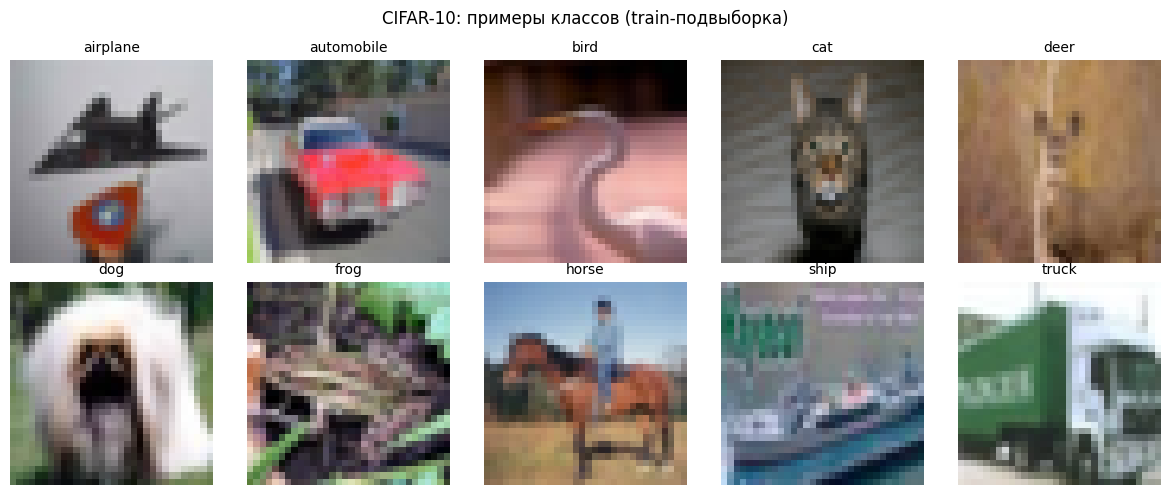

✔ Сохранено: artifacts\viz_class_samples.png


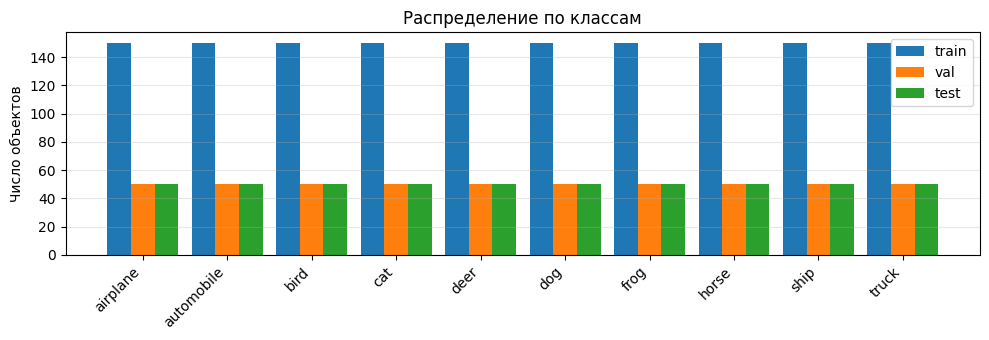

In [22]:
# ============================================================
# ЗАДАНИЕ 1. Стратифицированные разбиения CIFAR-10
# ============================================================
def stratified_train_val_split(targets, train_ratio=0.8, seed=42):
    targets = np.asarray(targets)
    rng = np.random.default_rng(seed)
    train_idx, val_idx = [], []
    for c in range(NUM_CLASSES):
        idx = np.where(targets == c)[0]
        rng.shuffle(idx)
        n_train = int(np.ceil(train_ratio * len(idx)))
        train_idx.extend(idx[:n_train].tolist())
        val_idx.extend(idx[n_train:].tolist())
    train_idx = np.array(train_idx); rng.shuffle(train_idx)
    val_idx = np.array(val_idx); rng.shuffle(val_idx)
    return train_idx, val_idx


def balanced_subsample_indices(indices, targets, n_total, seed):
    indices = np.asarray(indices); targets = np.asarray(targets)
    if n_total >= len(indices):
        return indices
    rng = np.random.default_rng(seed)
    per_class = max(1, n_total // NUM_CLASSES)
    selected = []
    for c in range(NUM_CLASSES):
        cls_idx = indices[targets[indices] == c]
        rng.shuffle(cls_idx)
        selected.extend(cls_idx[:per_class].tolist())
    selected = np.array(selected); rng.shuffle(selected)
    return selected[:n_total]


if FAST_DEV_RUN:
    TRAIN_LIMIT, VAL_LIMIT, TEST_LIMIT = 200, 100, 100
elif DEVICE == "cuda":
    TRAIN_LIMIT, VAL_LIMIT, TEST_LIMIT = 5000, 1000, 1000
else:
    TRAIN_LIMIT, VAL_LIMIT, TEST_LIMIT = 1500, 500, 500

train_full = CIFAR10(root=DATA_ROOT, train=True, download=True)
test_full = CIFAR10(root=DATA_ROOT, train=False, download=True)

train_targets = np.array(train_full.targets)
test_targets = np.array(test_full.targets)

train_idx, val_idx = stratified_train_val_split(train_targets, 0.8, SEED)
train_idx = balanced_subsample_indices(train_idx, train_targets, TRAIN_LIMIT, SEED + 10)
val_idx = balanced_subsample_indices(val_idx, train_targets, VAL_LIMIT, SEED + 11)
test_idx = balanced_subsample_indices(np.arange(len(test_full)), test_targets, TEST_LIMIT, SEED + 12)

manifest = {
    "device": DEVICE, "seed": SEED, "fast_dev_run": FAST_DEV_RUN,
    "train_limit": TRAIN_LIMIT, "val_limit": VAL_LIMIT, "test_limit": TEST_LIMIT,
    "n_train": int(len(train_idx)), "n_val": int(len(val_idx)), "n_test": int(len(test_idx)),
    "train_idx": [int(i) for i in train_idx],
    "val_idx": [int(i) for i in val_idx],
    "test_idx": [int(i) for i in test_idx],
}
save_json(ARTIFACTS / "dataset_manifest.json", manifest)

print(f"train: {len(train_idx)}")
print(f"val:   {len(val_idx)}")
print(f"test:  {len(test_idx)}")

check(len(set(train_targets[train_idx].tolist())) == NUM_CLASSES, "train содержит все 10 классов")
check(len(set(train_targets[val_idx].tolist())) == NUM_CLASSES, "val содержит все 10 классов")
check(len(set(test_targets[test_idx].tolist())) == NUM_CLASSES, "test содержит все 10 классов")

# ------------------------------------------------------------
# Визуализация: по одному примеру каждого класса
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
shown = {c: False for c in range(NUM_CLASSES)}
for i in train_idx:
    c = int(train_targets[i])
    if shown[c]:
        continue
    ax = axes[c // 5, c % 5]
    img, _ = train_full[int(i)]
    ax.imshow(img)
    ax.set_title(CLASS_NAMES[c], fontsize=10)
    ax.axis("off")
    shown[c] = True
    if all(shown.values()):
        break
plt.suptitle("CIFAR-10: примеры классов (train-подвыборка)", fontsize=12)
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_class_samples.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_class_samples.png'}")

# Гистограмма распределения классов
fig, ax = plt.subplots(1, 1, figsize=(10, 3.5))
cnt_tr = np.bincount(train_targets[train_idx], minlength=NUM_CLASSES)
cnt_v = np.bincount(train_targets[val_idx], minlength=NUM_CLASSES)
cnt_te = np.bincount(test_targets[test_idx], minlength=NUM_CLASSES)
x = np.arange(NUM_CLASSES); w = 0.28
ax.bar(x - w, cnt_tr, w, label="train")
ax.bar(x, cnt_v, w, label="val")
ax.bar(x + w, cnt_te, w, label="test")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("Число объектов")
ax.set_title("Распределение по классам")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_class_balance.png", dpi=120, bbox_inches="tight")
plt.show()

### Предобученный DINOv2 и признаки

*Вес: 1 балл.*

**Постановка.** Frozen encoder предоставляет представления без доступа к меткам при извлечении.

Выполните следующие действия:
1. Загрузите DINOv2 ViT-S/14.
2. Сохраните нормированные признаки и явные train/validation/test индексы.

**Результат.** embeddings.npz с фактическими DINO-признаками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [23]:
# ============================================================
# ЗАДАНИЕ 2. Предобученный DINOv2 и признаки
# ============================================================
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
INPUT_SIZE = 224

eval_transform = T.Compose([
    T.Resize(INPUT_SIZE),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class CIFARView(Dataset):
    def __init__(self, base, indices, transform=None):
        self.base = base
        self.indices = np.asarray(indices)
        self.transform = transform
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        idx = int(self.indices[i])
        img, label = self.base[idx]
        if not isinstance(img, Image.Image):
            img = Image.fromarray(img)
        if self.transform is not None:
            img = self.transform(img)
        return img, int(label), idx


class EncoderWrapper(nn.Module):
    def __init__(self, backbone, kind):
        super().__init__()
        self.backbone = backbone
        self.kind = kind
    def forward(self, x):
        out = self.backbone(x)
        if isinstance(out, dict):
            for key in ["x_norm_clstoken", "cls_token", "x_norm", "features", "last_hidden_state"]:
                if key in out:
                    out = out[key]; break
            else:
                out = next(iter(out.values()))
        if isinstance(out, (list, tuple)):
            out = out[0]
        if out.dim() == 4:
            out = out.mean(dim=[2, 3])
        if out.dim() == 3:
            if out.size(1) in (197, 257, 137):
                out = out[:, 0]
            else:
                out = out.mean(dim=1)
        if out.dim() != 2:
            out = out.flatten(1)
        return F.normalize(out, dim=1)


def infer_embed_dim(wrapper):
    wrapper.eval()
    with torch.no_grad():
        dummy = torch.randn(1, 3, INPUT_SIZE, INPUT_SIZE, device=DEVICE)
        out = wrapper(dummy)
    return int(out.shape[1])


def build_encoder(prefer_dino=True):
    errors = []
    if prefer_dino:
        try:
            try:
                backbone = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14",
                                          pretrained=True, trust_repo=True)
            except TypeError:
                backbone = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14",
                                          pretrained=True)
            backbone.eval()
            wrapper = EncoderWrapper(backbone, "dinov2").to(DEVICE).eval()
            return wrapper, "dinov2_vits14", infer_embed_dim(wrapper)
        except Exception as e:
            errors.append(f"DINOv2: {e}")
    try:
        from torchvision.models import resnet18, ResNet18_Weights
        backbone = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        backbone.fc = nn.Identity()
        backbone.eval()
        wrapper = EncoderWrapper(backbone, "resnet18").to(DEVICE).eval()
        return wrapper, "resnet18", infer_embed_dim(wrapper)
    except Exception as e:
        errors.append(f"ResNet18: {e}")
        raise RuntimeError("Не удалось загрузить энкодер.\n" + "\n".join(errors))


def extract_features(encoder, dataset, indices, transform, batch_size=32, tag=""):
    ds_view = CIFARView(dataset, indices, transform)
    dl = DataLoader(ds_view, batch_size=batch_size, shuffle=False, num_workers=0)
    feats, labels, actual_idx = [], [], []
    encoder.eval()
    use_amp = DEVICE == "cuda"
    with torch.no_grad():
        for k, (imgs, y, idx) in enumerate(dl):
            imgs = imgs.to(DEVICE, non_blocking=True)
            if use_amp:
                with torch.cuda.amp.autocast():
                    f = encoder(imgs)
            else:
                f = encoder(imgs)
            f = F.normalize(f.float(), dim=1)
            feats.append(f.cpu()); labels.append(y); actual_idx.append(idx)
            if tag and ((k + 1) % 10 == 0):
                print(f" [{tag}] {k+1}/{len(dl)}", flush=True)
    return torch.cat(feats), torch.cat(labels), torch.cat(actual_idx)


print("Загрузка предобученного энкодера...")
encoder, ENCODER_NAME, EMBED_DIM = build_encoder(prefer_dino=True)
print(f"Энкодер: {ENCODER_NAME}, dim={EMBED_DIM}")

save_json(ARTIFACTS / "encoder_meta.json", {
    "encoder_name": ENCODER_NAME, "embed_dim": EMBED_DIM,
    "input_size": INPUT_SIZE, "device": DEVICE,
    "mean": IMAGENET_MEAN, "std": IMAGENET_STD,
})

FEATURES_PATH = ARTIFACTS / "features.pt"
FEATURE_CONFIG = {"encoder": ENCODER_NAME, "input": INPUT_SIZE,
                  "n_train": len(train_idx), "n_val": len(val_idx), "n_test": len(test_idx)}
FEATURE_HASH = config_hash(FEATURE_CONFIG)

if FEATURES_PATH.exists():
    blob = torch.load(FEATURES_PATH, map_location="cpu")
    if blob.get("config_hash") == FEATURE_HASH:
        print("Найден features.pt с совпадающим конфигом — загружаю.")
        X_train, y_train, idx_train = blob["X_train"], blob["y_train"], blob["idx_train"]
        X_val,   y_val,   idx_val   = blob["X_val"],   blob["y_val"],   blob["idx_val"]
        X_test,  y_test,  idx_test  = blob["X_test"],  blob["y_test"],  blob["idx_test"]
    else:
        print("Конфиг features.pt устарел — пересчитываю.")
        FEATURES_PATH.unlink()

if not FEATURES_PATH.exists():
    print("Извлечение признаков (frozen)...")
    bs = 64 if DEVICE == "cuda" else 32
    X_train, y_train, idx_train = extract_features(encoder, train_full, train_idx, eval_transform, bs, "train")
    X_val,   y_val,   idx_val   = extract_features(encoder, train_full, val_idx,   eval_transform, bs, "val")
    X_test,  y_test,  idx_test  = extract_features(encoder, test_full,  test_idx,  eval_transform, bs, "test")
    torch.save({
        "encoder_name": ENCODER_NAME, "embed_dim": EMBED_DIM,
        "config_hash": FEATURE_HASH,
        "X_train": X_train, "y_train": y_train, "idx_train": idx_train,
        "X_val":   X_val,   "y_val":   y_val,   "idx_val":   idx_val,
        "X_test":  X_test,  "y_test":  y_test,  "idx_test":  idx_test,
    }, FEATURES_PATH)

print(f"X_train: {tuple(X_train.shape)}")
print(f"X_val:   {tuple(X_val.shape)}")
print(f"X_test:  {tuple(X_test.shape)}")
check(X_train.shape[1] == EMBED_DIM, "размерность совпадает")
check(abs(float(torch.norm(X_train[0]).item()) - 1.0) < 1e-3, "L2-норма ≈ 1")

Загрузка предобученного энкодера...


Using cache found in C:\Users\User/.cache\torch\hub\facebookresearch_dinov2_main


Энкодер: dinov2_vits14, dim=384
Извлечение признаков (frozen)...
 [train] 10/47
 [train] 20/47
 [train] 30/47
 [train] 40/47
 [val] 10/16
 [test] 10/16
X_train: (1500, 384)
X_val:   (500, 384)
X_test:  (500, 384)
✔ размерность совпадает
✔ L2-норма ≈ 1


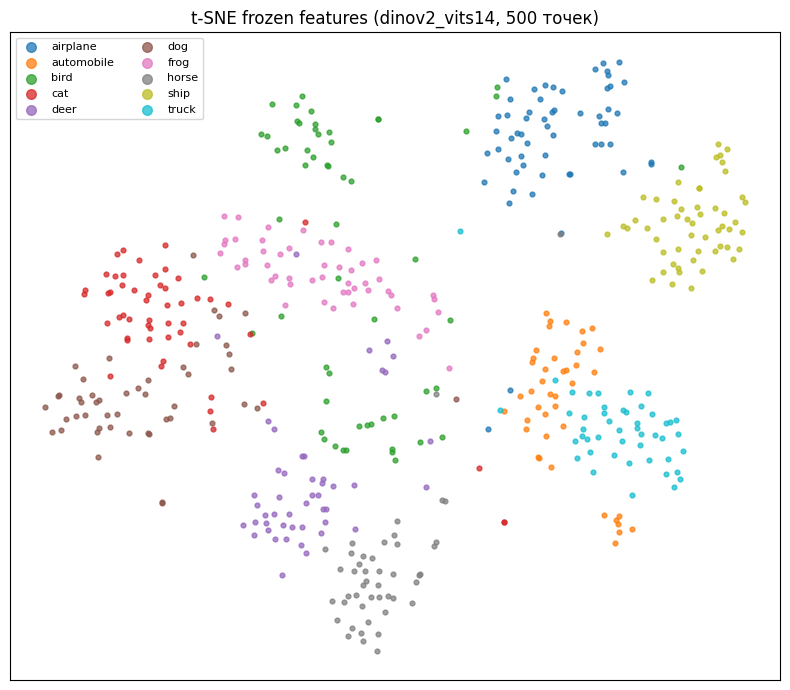

✔ Сохранено: artifacts\viz_tsne_frozen.png


In [24]:
# ============================================================
# Визуализация frozen-признаков: t-SNE
# ============================================================
def reduce_2d(X, seed=42):
    """t-SNE с fallback на PCA."""
    X_np = X.numpy() if torch.is_tensor(X) else X
    try:
        from sklearn.manifold import TSNE
        tsne = TSNE(n_components=2, perplexity=30, random_state=seed,
                    init="pca", learning_rate="auto")
        return tsne.fit_transform(X_np)
    except ImportError:
        X_t = torch.as_tensor(X_np, dtype=torch.float32)
        X_c = X_t - X_t.mean(dim=0, keepdim=True)
        _, _, V = torch.svd(X_c)
        return (X_c @ V[:, :2]).numpy()


N_VIS = min(500, len(X_train))
rng = np.random.default_rng(SEED)
vis_rows = rng.choice(len(X_train), size=N_VIS, replace=False)
Y2 = reduce_2d(X_train[vis_rows], seed=SEED)
labels_vis = y_train[vis_rows].numpy()

fig, ax = plt.subplots(figsize=(8, 7))
cmap = plt.get_cmap("tab10")
for c in range(NUM_CLASSES):
    m = labels_vis == c
    ax.scatter(Y2[m, 0], Y2[m, 1], s=12, color=cmap(c), label=CLASS_NAMES[c], alpha=0.75)
ax.set_title(f"t-SNE frozen features ({ENCODER_NAME}, {N_VIS} точек)")
ax.legend(markerscale=2, fontsize=8, ncol=2)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_tsne_frozen.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_tsne_frozen.png'}")

### Подбор k-NN на validation

*Вес: 1 балл.*

**Постановка.** Число соседей следует выбирать без обращения к test.

Выполните следующие действия:
1. Обучите k-NN для предложенной сетки k.
2. Выберите k по validation accuracy.

**Результат.** Словарь knn_val и выбранный best_k.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Подбор k на validation...
k=  1 | val_acc=0.8920
k=  3 | val_acc=0.9020
k=  5 | val_acc=0.9060
k=  7 | val_acc=0.9160
k= 10 | val_acc=0.9220
k= 20 | val_acc=0.9200
k= 50 | val_acc=0.9160
Лучший k: 10, val_acc=0.9220
✔ best_k из допустимого списка


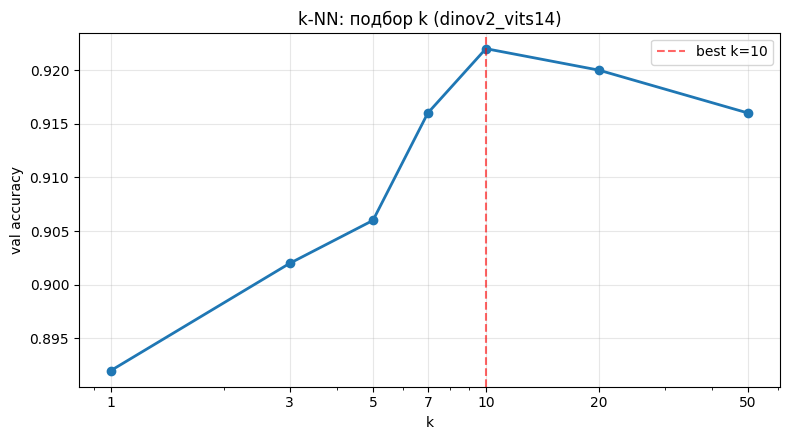

In [25]:
# ============================================================
# ЗАДАНИЕ 3. Подбор k-NN на validation
# ============================================================
def knn_predict(train_features, train_labels, query_features, k, temperature=0.1):
    k = min(k, len(train_features))
    tf = F.normalize(train_features.to(DEVICE), dim=1)
    qf = F.normalize(query_features.to(DEVICE), dim=1)
    tl = train_labels.to(DEVICE)
    sims = qf @ tf.T
    top_sims, top_idx = sims.topk(k, dim=1)
    top_labels = tl[top_idx]
    w = torch.exp(top_sims / temperature)
    votes = torch.zeros(qf.size(0), NUM_CLASSES, device=DEVICE)
    votes.scatter_add_(1, top_labels, w)
    return votes.argmax(dim=1).cpu()


def accuracy_score(pred, target):
    return float(np.mean(np.asarray(pred) == np.asarray(target)))


K_LIST = [k for k in [1, 3, 5, 7, 10, 20, 50] if k <= len(X_train)]

knn_val_rows = []
print("Подбор k на validation...")
for k in K_LIST:
    pred = knn_predict(X_train, y_train, X_val, k=k)
    acc = accuracy_score(pred, y_val)
    knn_val_rows.append({"k": int(k), "val_accuracy": acc})
    print(f"k={k:>3} | val_acc={acc:.4f}")

best_knn = max(knn_val_rows, key=lambda r: r["val_accuracy"])
BEST_K = int(best_knn["k"])

save_json(ARTIFACTS / "knn_val.json", {
    "device": DEVICE, "seed": SEED, "encoder_name": ENCODER_NAME,
    "temperature": 0.1, "results": knn_val_rows,
    "best_k": BEST_K, "best_val_accuracy": best_knn["val_accuracy"],
})

print(f"Лучший k: {BEST_K}, val_acc={best_knn['val_accuracy']:.4f}")
check(BEST_K in K_LIST, "best_k из допустимого списка")

# ------------------------------------------------------------
# Кривая val accuracy vs k
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4.5))
ks = [r["k"] for r in knn_val_rows]
accs = [r["val_accuracy"] for r in knn_val_rows]
ax.plot(ks, accs, marker="o", linewidth=2)
ax.axvline(BEST_K, color="red", linestyle="--", alpha=0.6, label=f"best k={BEST_K}")
ax.set_xscale("log")
ax.set_xticks(ks); ax.set_xticklabels([str(k) for k in ks])
ax.set_xlabel("k"); ax.set_ylabel("val accuracy")
ax.set_title(f"k-NN: подбор k ({ENCODER_NAME})")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_knn_k_curve.png", dpi=120, bbox_inches="tight")
plt.show()

### Линейная проверка и test

*Вес: 1 балл.*

**Постановка.** Frozen-признаки оценивают независимыми простыми классификаторами.

Выполните следующие действия:
1. Обучите k-NN и logistic regression только на train.
2. Вычислите test accuracy и macro-F1 после выбора k.

**Результат.** probes.json с измеренными test-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Обучение линейного probe (frozen)...
linear | val_acc=0.9380 | test_acc=0.9240 | test_f1=0.9240
k-NN с k=10...
k-NN   | val_acc=0.9220 | test_acc=0.9200 | test_f1=0.9192
✔ linear probe дал ненулевую точность
✔ k-NN дал ненулевую точность


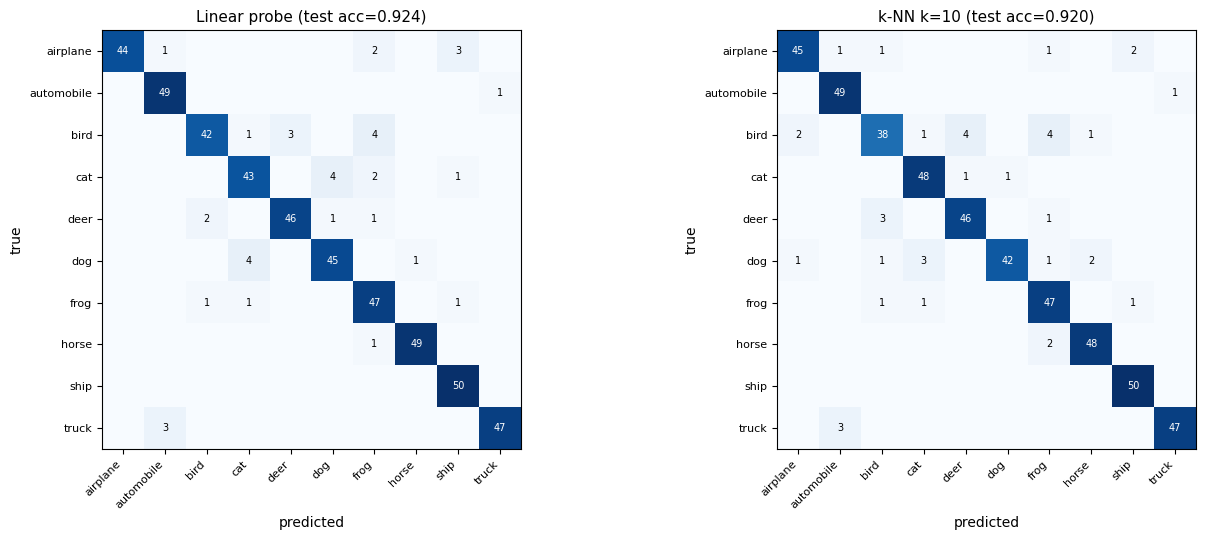

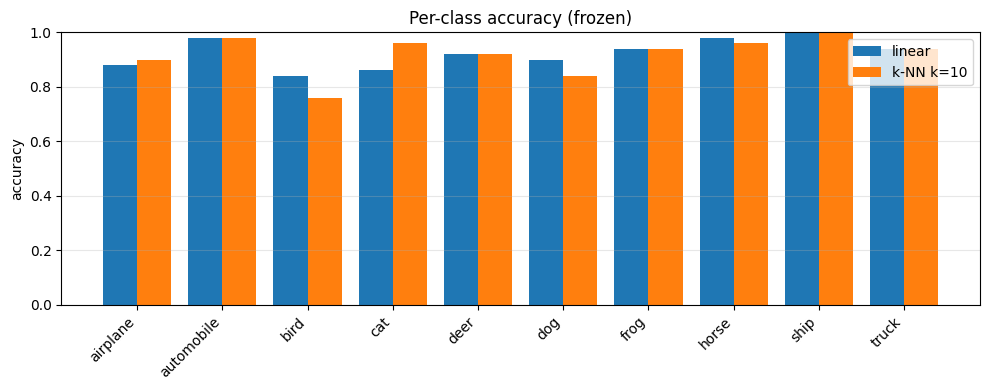

In [26]:
# ============================================================
# ЗАДАНИЕ 4. Линейная проверка и test
# ============================================================
def macro_f1(y_true, y_pred, num_classes=NUM_CLASSES):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    f1s = []
    for c in range(num_classes):
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        if tp == 0:
            f1s.append(0.0); continue
        p = tp / (tp + fp); r = tp / (tp + fn)
        f1s.append(2 * p * r / (p + r))
    return float(np.mean(f1s))


def confusion_matrix(y_true, y_pred, num_classes=NUM_CLASSES):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[int(t), int(p)] += 1
    return cm


def train_linear_probe(X_tr, y_tr, embed_dim, max_iter=100, lr=0.1):
    model = nn.Linear(embed_dim, NUM_CLASSES).to(DEVICE)
    X_tt = torch.as_tensor(X_tr, dtype=torch.float32, device=DEVICE)
    y_tt = torch.as_tensor(y_tr, dtype=torch.long, device=DEVICE)
    opt = torch.optim.LBFGS(model.parameters(), lr=lr, max_iter=max_iter)
    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(model(X_tt), y_tt)
        loss.backward()
        return loss
    opt.step(closure)
    return model


def evaluate_model(model, X, y):
    model.eval()
    X_t = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        pred = model(X_t).argmax(dim=1).cpu()
    return accuracy_score(pred, np.asarray(y)), macro_f1(np.asarray(y), pred.numpy())


print("Обучение линейного probe (frozen)...")
linear = train_linear_probe(X_train, y_train, EMBED_DIM, max_iter=100)
linear_val_acc, linear_val_f1 = evaluate_model(linear, X_val, y_val)
linear_test_acc, linear_test_f1 = evaluate_model(linear, X_test, y_test)
print(f"linear | val_acc={linear_val_acc:.4f} | test_acc={linear_test_acc:.4f} | test_f1={linear_test_f1:.4f}")

print(f"k-NN с k={BEST_K}...")
knn_test_pred = knn_predict(X_train, y_train, X_test, k=BEST_K)
knn_val_pred = knn_predict(X_train, y_train, X_val, k=BEST_K)
knn_test_acc = accuracy_score(knn_test_pred, y_test)
knn_test_f1 = macro_f1(y_test, knn_test_pred.numpy())
knn_val_acc = accuracy_score(knn_val_pred, y_val)
print(f"k-NN   | val_acc={knn_val_acc:.4f} | test_acc={knn_test_acc:.4f} | test_f1={knn_test_f1:.4f}")

# Предсказания линейного probe на test
with torch.no_grad():
    lin_pred = linear(torch.as_tensor(X_test, dtype=torch.float32, device=DEVICE)).argmax(1).cpu().numpy()

save_json(ARTIFACTS / "probes.json", {
    "device": DEVICE, "seed": SEED, "encoder_name": ENCODER_NAME,
    "n_train": int(len(X_train)), "n_val": int(len(X_val)), "n_test": int(len(X_test)),
    "best_k": BEST_K,
    "knn": {"val_accuracy": knn_val_acc, "test_accuracy": knn_test_acc, "test_macro_f1": knn_test_f1},
    "linear": {"val_accuracy": linear_val_acc, "val_macro_f1": linear_val_f1,
               "test_accuracy": linear_test_acc, "test_macro_f1": linear_test_f1},
})

check(linear_test_acc > 0.0, "linear probe дал ненулевую точность")
check(knn_test_acc > 0.0, "k-NN дал ненулевую точность")

# ------------------------------------------------------------
# Confusion matrices
# ------------------------------------------------------------
def plot_cm(ax, cm, title):
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=11)
    thr = cm.max() / 2 if cm.max() > 0 else 0
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cm[i, j] == 0: continue
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > thr else "black")
    return im

cm_linear = confusion_matrix(y_test.numpy(), lin_pred)
cm_knn = confusion_matrix(y_test.numpy(), knn_test_pred.numpy())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_cm(axes[0], cm_linear, f"Linear probe (test acc={linear_test_acc:.3f})")
plot_cm(axes[1], cm_knn, f"k-NN k={BEST_K} (test acc={knn_test_acc:.3f})")
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_confusion_frozen.png", dpi=120, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Per-class accuracy
# ------------------------------------------------------------
per_class = []
for c in range(NUM_CLASSES):
    m = y_test.numpy() == c
    per_class.append({
        "class": CLASS_NAMES[c],
        "linear_acc": float(np.mean(lin_pred[m] == c)),
        "knn_acc":    float(np.mean(knn_test_pred.numpy()[m] == c)),
    })

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(NUM_CLASSES); w = 0.4
ax.bar(x - w/2, [r["linear_acc"] for r in per_class], w, label="linear")
ax.bar(x + w/2, [r["knn_acc"]    for r in per_class], w, label=f"k-NN k={BEST_K}")
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("accuracy"); ax.set_ylim(0, 1)
ax.set_title("Per-class accuracy (frozen)")
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_per_class_frozen.png", dpi=120, bbox_inches="tight")
plt.show()

### Кривая объёма разметки

*Вес: 1 балл.*

**Постановка.** Малые размеченные подмножества выявляют sample efficiency представления.

Выполните следующие действия:
1. Создайте сбалансированные подмножества train по фиксированному seed.
2. Обучите отдельный linear probe для каждой доли и сохраните результаты.

**Результат.** label_curve.json с числом объектов и измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Кривая объёма разметки...
frac= 0.01 | n=   10 | val_acc=0.6420 | test_acc=0.6480
frac= 0.05 | n=   70 | val_acc=0.8520 | test_acc=0.8600
frac= 0.10 | n=  150 | val_acc=0.9100 | test_acc=0.8840
frac= 0.25 | n=  370 | val_acc=0.9280 | test_acc=0.8880
frac= 0.50 | n=  750 | val_acc=0.9440 | test_acc=0.9220
frac= 1.00 | n= 1500 | val_acc=0.9360 | test_acc=0.9280


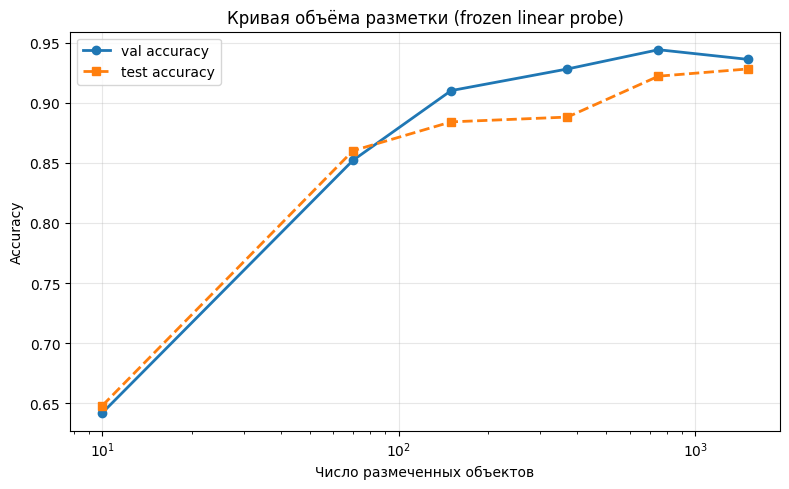

✔ Сохранено: artifacts\label_curve.json


In [27]:
# ============================================================
# ЗАДАНИЕ 5. Кривая объёма разметки
# ============================================================
def balanced_subsample_rows(labels, n_total, seed):
    labels = np.asarray(labels)
    if n_total >= len(labels):
        return np.arange(len(labels))
    rng = np.random.default_rng(seed)
    per_class = max(1, n_total // NUM_CLASSES)
    rows = []
    for c in range(NUM_CLASSES):
        cls = np.where(labels == c)[0]; rng.shuffle(cls)
        rows.extend(cls[:per_class].tolist())
    rows = np.array(rows); rng.shuffle(rows)
    return rows[:n_total]

FRACTIONS = [0.01, 0.05, 0.10, 0.25, 0.50, 1.00]
label_curve = []

print("Кривая объёма разметки...")
for frac in FRACTIONS:
    n_samples = max(NUM_CLASSES, int(round(len(y_train) * frac)))
    rows = balanced_subsample_rows(y_train.numpy(), n_samples, seed=SEED + int(frac * 1000))
    X_sub, y_sub = X_train[rows], y_train[rows]
    max_iter = 200 if len(rows) < 500 else 100
    m = train_linear_probe(X_sub, y_sub, EMBED_DIM, max_iter=max_iter)
    val_acc, val_f1 = evaluate_model(m, X_val, y_val)
    test_acc, test_f1 = evaluate_model(m, X_test, y_test)
    label_curve.append({
        "fraction": frac, "n_samples": int(len(rows)),
        "val_accuracy": val_acc, "val_macro_f1": val_f1,
        "test_accuracy": test_acc, "test_macro_f1": test_f1,
    })
    print(f"frac={frac:5.2f} | n={len(rows):5d} | val_acc={val_acc:.4f} | test_acc={test_acc:.4f}")

save_json(ARTIFACTS / "label_curve.json", label_curve)

fig, ax = plt.subplots(figsize=(8, 5))
ns = [r["n_samples"] for r in label_curve]
va = [r["val_accuracy"] for r in label_curve]
ta = [r["test_accuracy"] for r in label_curve]
ax.plot(ns, va, marker="o", linewidth=2, label="val accuracy")
ax.plot(ns, ta, marker="s", linestyle="--", linewidth=2, label="test accuracy")
ax.set_xscale("log")
ax.set_xlabel("Число размеченных объектов")
ax.set_ylabel("Accuracy")
ax.set_title("Кривая объёма разметки (frozen linear probe)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_label_curve.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'label_curve.json'}")

### Контрастивная адаптация encoder

*Вес: 1 балл.*

**Постановка.** Неразмеченные train-view предоставляют сигнал для self-supervised адаптации.

Выполните следующие действия:
1. Создайте две аугментации одних train-изображений.
2. Оптимизируйте InfoNCE и сохраните обновлённый encoder.

**Результат.** encoder_adapted.pt после реальных optimizer steps.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


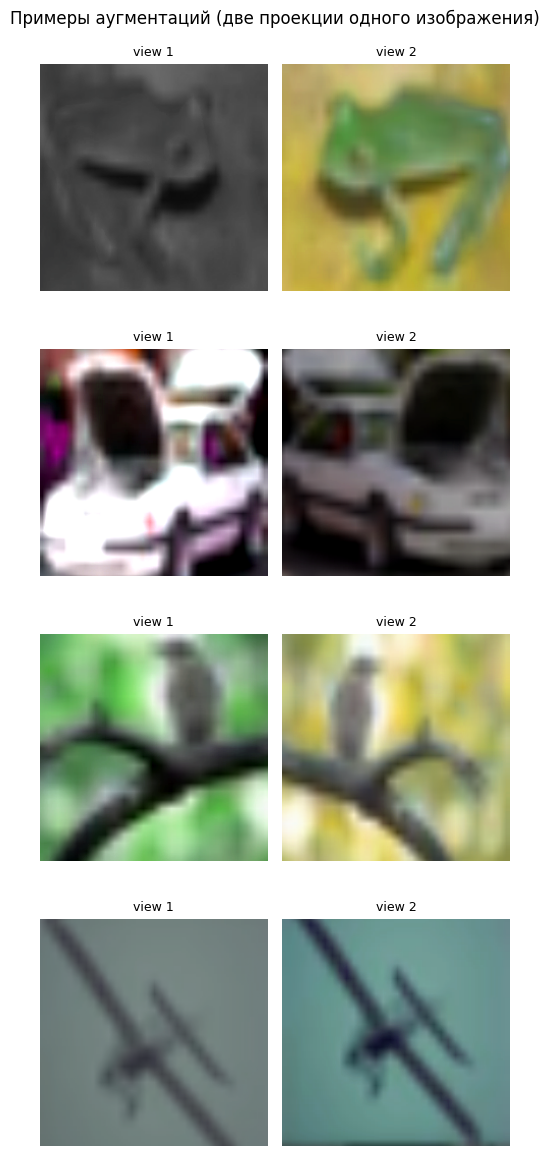

In [28]:
# ============================================================
# Аугментации: примеры двух views
# ============================================================
contrastive_transform = T.Compose([
    T.Resize(INPUT_SIZE),
    T.RandomResizedCrop(INPUT_SIZE, scale=(0.6, 1.0)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(0.4, 0.4, 0.4, 0.1),
    T.RandomGrayscale(p=0.2),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class TwoViewCIFAR(Dataset):
    def __init__(self, base, indices, transform):
        self.base = base; self.indices = np.asarray(indices); self.transform = transform
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        idx = int(self.indices[i])
        img, _ = self.base[idx]
        if not isinstance(img, Image.Image):
            img = Image.fromarray(img)
        return self.transform(img), self.transform(img)

# Показываем 4 примера по 2 views
rng = np.random.default_rng(SEED)
demo_rows = rng.choice(len(train_idx), size=4, replace=False)
demo_ds = TwoViewCIFAR(train_full, train_idx[demo_rows], contrastive_transform)

def denorm(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(4, 2, figsize=(5, 12))
for r in range(4):
    v1, v2 = demo_ds[r]
    axes[r, 0].imshow(denorm(v1)); axes[r, 0].axis("off")
    axes[r, 0].set_title("view 1", fontsize=9)
    axes[r, 1].imshow(denorm(v2)); axes[r, 1].axis("off")
    axes[r, 1].set_title("view 2", fontsize=9)
plt.suptitle("Примеры аугментаций (две проекции одного изображения)", fontsize=12)
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_augmentations.png", dpi=120, bbox_inches="tight")
plt.show()

Контрастивная адаптация энкодера...
Адаптация: 400 изображений, 6 эпох, batch=16, обучаемых параметров=3.749M
epoch 1/6 | step 10/25 | loss=0.5031
epoch 1/6 | step 20/25 | loss=0.3120
epoch 1/6 | step 25/25 | loss=0.4628
Epoch 1/6: loss=0.7346, time=139.2s
epoch 2/6 | step 10/25 | loss=0.1223
epoch 2/6 | step 20/25 | loss=0.3147
epoch 2/6 | step 25/25 | loss=0.0784
Epoch 2/6: loss=0.1534, time=120.4s
epoch 3/6 | step 10/25 | loss=0.0628
epoch 3/6 | step 20/25 | loss=0.1025
epoch 3/6 | step 25/25 | loss=0.3045
Epoch 3/6: loss=0.1111, time=121.6s
epoch 4/6 | step 10/25 | loss=0.0996
epoch 4/6 | step 20/25 | loss=0.0341
epoch 4/6 | step 25/25 | loss=0.0791
Epoch 4/6: loss=0.0881, time=123.1s
epoch 5/6 | step 10/25 | loss=0.0760
epoch 5/6 | step 20/25 | loss=0.0881
epoch 5/6 | step 25/25 | loss=0.0402
Epoch 5/6: loss=0.0613, time=118.5s
epoch 6/6 | step 10/25 | loss=0.0778
epoch 6/6 | step 20/25 | loss=0.0732
epoch 6/6 | step 25/25 | loss=0.0315
Epoch 6/6: loss=0.0588, time=119.5s
✔ Сохран

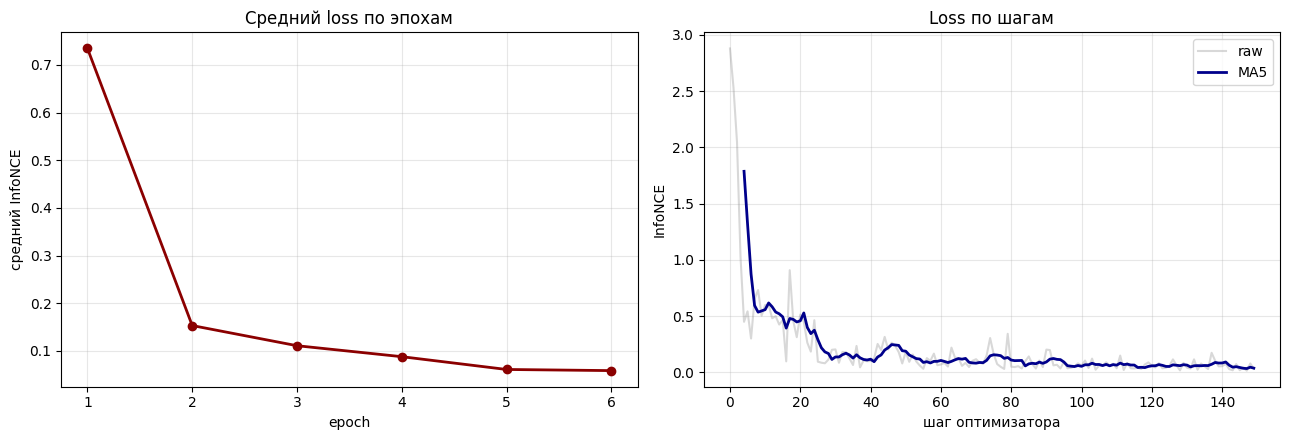

✔ Сохранено: artifacts\viz_contrastive_loss.png


In [29]:
# ============================================================
# ЗАДАНИЕ 6. Контрастивная адаптация encoder
# ============================================================
class ContrastiveModel(nn.Module):
    def __init__(self, encoder, embed_dim, proj_dim=128):
        super().__init__()
        self.encoder = encoder
        self.proj = nn.Sequential(
            nn.Linear(embed_dim, embed_dim), nn.ReLU(inplace=True),
            nn.Linear(embed_dim, proj_dim),
        )
    def forward(self, x):
        z = self.encoder(x)
        z = self.proj(z)
        return F.normalize(z, dim=1)


def info_nce_loss(z1, z2, temperature=0.1):
    n = z1.size(0)
    z = F.normalize(torch.cat([z1, z2], dim=0), dim=1)
    logits = z @ z.T / temperature
    self_mask = torch.eye(2 * n, dtype=torch.bool, device=logits.device)
    logits = logits.masked_fill(self_mask, -1e9)
    pos = torch.cat([torch.arange(n, 2 * n, device=logits.device),
                     torch.arange(0, n, device=logits.device)])
    return F.cross_entropy(logits, pos)


def prepare_encoder_for_adaptation(encoder, encoder_name):
    for p in encoder.parameters():
        p.requires_grad = False
    bb = getattr(encoder, "backbone", None)
    if "dinov2" in encoder_name and bb is not None and hasattr(bb, "blocks"):
        for block in bb.blocks[-2:]:
            for p in block.parameters():
                p.requires_grad = True
        if hasattr(bb, "norm"):
            for p in bb.norm.parameters():
                p.requires_grad = True
        p = getattr(bb, "cls_token", None)
        if isinstance(p, nn.Parameter):
            p.requires_grad = True
    elif "resnet" in encoder_name and bb is not None:
        for p in bb.layer4.parameters():
            p.requires_grad = True
    else:
        for p in encoder.parameters():
            p.requires_grad = True
    return encoder


# ------------------------------------------------------------
# Объём адаптации: делаем ставку на несколько эпох
# ------------------------------------------------------------
if FAST_DEV_RUN:
    ADAPT_LIMIT, ADAPT_EPOCHS = 80, 2
elif DEVICE == "cuda":
    ADAPT_LIMIT, ADAPT_EPOCHS = 2000, 10
else:
    ADAPT_LIMIT, ADAPT_EPOCHS = 400, 6   # CPU: 6 эпох вместо 1

ADAPT_BATCH   = 16
ADAPT_TEMP    = 0.1
ENCODER_LR    = 2e-6 if "dinov2" in ENCODER_NAME else 1e-4
PROJ_LR       = 1e-3
WEIGHT_DECAY  = 1e-4

adapt_idx = balanced_subsample_indices(train_idx, train_targets, ADAPT_LIMIT, seed=SEED + 100)

ADAPT_CONFIG = {
    "limit": ADAPT_LIMIT, "epochs": ADAPT_EPOCHS, "batch": ADAPT_BATCH,
    "temp": ADAPT_TEMP, "encoder_lr": ENCODER_LR, "proj_lr": PROJ_LR,
    "wd": WEIGHT_DECAY, "encoder": ENCODER_NAME,
}
ADAPT_HASH = config_hash(ADAPT_CONFIG)

ADAPTATION_PATH = ARTIFACTS / "adaptation.pt"
need_train = True
if ADAPTATION_PATH.exists():
    blob = torch.load(ADAPTATION_PATH, map_location="cpu")
    if blob.get("config_hash") == ADAPT_HASH:
        print("Найден adaptation.pt с совпадающим конфигом — загружаю.")
        adapted_encoder = copy.deepcopy(encoder).to(DEVICE)
        adapted_encoder.load_state_dict(blob["encoder_state_dict"])
        adapted_encoder.eval()
        adapt_loss_history = blob.get("loss_history", [])
        need_train = False
    else:
        print("Конфиг adaptation.pt устарел — переобучаю.")
        ADAPTATION_PATH.unlink()

if need_train:
    print("Контрастивная адаптация энкодера...")
    adapted_encoder = copy.deepcopy(encoder).to(DEVICE)
    adapted_encoder = prepare_encoder_for_adaptation(adapted_encoder, ENCODER_NAME)

    contrastive = ContrastiveModel(adapted_encoder, EMBED_DIM).to(DEVICE)

    enc_params  = [p for p in contrastive.encoder.parameters() if p.requires_grad]
    proj_params = list(contrastive.proj.parameters())

    param_groups = [{"params": proj_params, "lr": PROJ_LR}]
    if len(enc_params) > 0:
        param_groups.append({"params": enc_params, "lr": ENCODER_LR})

    optimizer = torch.optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=ADAPT_EPOCHS)

    contrastive_ds = TwoViewCIFAR(train_full, adapt_idx, contrastive_transform)
    contrastive_loader = DataLoader(contrastive_ds, batch_size=ADAPT_BATCH,
                                    shuffle=True, drop_last=True, num_workers=0)

    n_trainable = sum(p.numel() for p in contrastive.parameters() if p.requires_grad)
    print(f"Адаптация: {len(contrastive_ds)} изображений, {ADAPT_EPOCHS} эпох, "
          f"batch={ADAPT_BATCH}, обучаемых параметров={n_trainable/1e6:.3f}M")

    adapt_loss_history = []
    step_losses = []   # для плавной кривой

    for epoch in range(1, ADAPT_EPOCHS + 1):
        contrastive.train()
        epoch_loss, n_batches = 0.0, 0
        t0 = time.time()
        for step, (x1, x2) in enumerate(contrastive_loader):
            x1 = x1.to(DEVICE, non_blocking=True)
            x2 = x2.to(DEVICE, non_blocking=True)

            z1 = contrastive(x1); z2 = contrastive(x2)
            loss = info_nce_loss(z1, z2, temperature=ADAPT_TEMP)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                [p for p in contrastive.parameters() if p.requires_grad], 1.0)
            optimizer.step()

            epoch_loss += loss.item(); n_batches += 1
            step_losses.append({"epoch": epoch, "step": step, "loss": loss.item()})

            if (step + 1) % 10 == 0 or (step + 1) == len(contrastive_loader):
                print(f"epoch {epoch}/{ADAPT_EPOCHS} | step {step+1}/{len(contrastive_loader)} "
                      f"| loss={loss.item():.4f}", flush=True)

        scheduler.step()
        avg = epoch_loss / max(1, n_batches)
        adapt_loss_history.append({"epoch": epoch, "loss": avg, "time_sec": time.time() - t0})
        print(f"Epoch {epoch}/{ADAPT_EPOCHS}: loss={avg:.4f}, time={time.time()-t0:.1f}s")

    adapted_encoder.eval()
    torch.save({
        "encoder_name": ENCODER_NAME, "embed_dim": EMBED_DIM,
        "config_hash": ADAPT_HASH, "config": ADAPT_CONFIG,
        "encoder_state_dict": adapted_encoder.state_dict(),
        "loss_history": adapt_loss_history, "step_losses": step_losses,
    }, ADAPTATION_PATH)
    print(f"✔ Сохранено: {ADAPTATION_PATH}")

# ------------------------------------------------------------
# Кривая обучения
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

if adapt_loss_history:
    ep = [h["epoch"] for h in adapt_loss_history]
    ls = [h["loss"] for h in adapt_loss_history]
    axes[0].plot(ep, ls, marker="o", linewidth=2, color="darkred")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("средний InfoNCE")
    axes[0].set_title("Средний loss по эпохам")
    axes[0].grid(alpha=0.3)

# Плавная кривая по шагам
try:
    sl = step_losses
except NameError:
    blob = torch.load(ADAPTATION_PATH, map_location="cpu")
    sl = blob.get("step_losses", [])

if sl:
    xs = np.arange(len(sl))
    ys = np.array([r["loss"] for r in sl])
    # Скользящее среднее
    win = max(1, len(ys) // 30)
    ys_smooth = np.convolve(ys, np.ones(win) / win, mode="valid")
    axes[1].plot(xs, ys, alpha=0.3, color="gray", label="raw")
    axes[1].plot(xs[win-1:], ys_smooth, linewidth=2, color="darkblue", label=f"MA{win}")
    axes[1].set_xlabel("шаг оптимизатора"); axes[1].set_ylabel("InfoNCE")
    axes[1].set_title("Loss по шагам")
    axes[1].grid(alpha=0.3); axes[1].legend()

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_contrastive_loss.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_contrastive_loss.png'}")

### Признаки после адаптации

*Вес: 1 балл.*

**Постановка.** Сравнение до и после адаптации требует одних и тех же изображений.

Выполните следующие действия:
1. Пересчитайте признаки train/validation/test обновлённым encoder.
2. Обучите новый linear probe на train.

**Результат.** Матрица X_new и обученный new_linear.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Извлечение признаков после адаптации...
 [adapted-train] 10/47
 [adapted-train] 20/47
 [adapted-train] 30/47
 [adapted-train] 40/47
 [adapted-val] 10/16
 [adapted-test] 10/16
✔ Сохранено: artifacts\adapted_features.pt
Обучение linear probe на адаптированных признаках...
✔ Сохранено: artifacts\adapted_linear.pt


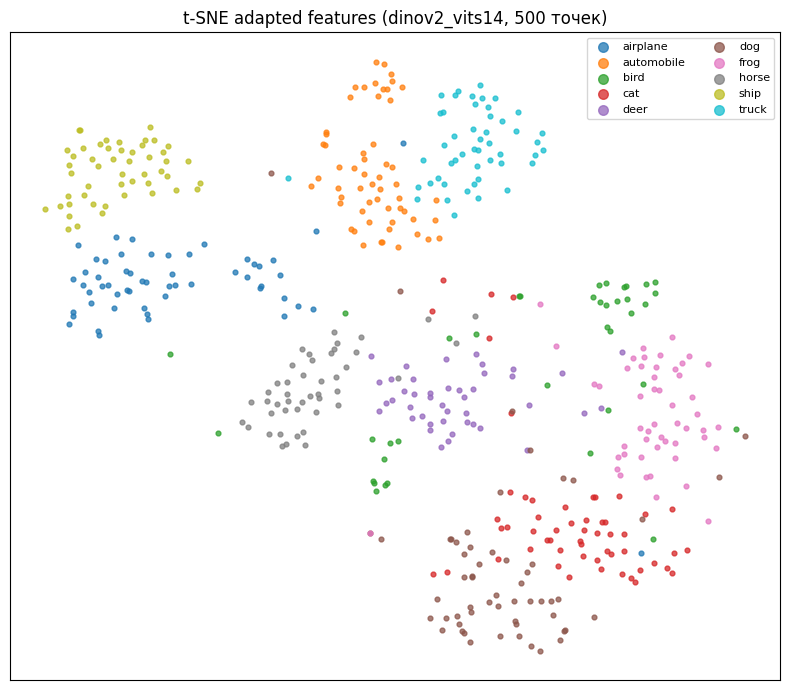

✔ Сохранено: artifacts\viz_tsne_adapted.png


In [30]:
# ============================================================
# ЗАДАНИЕ 7. Признаки после адаптации
# ============================================================
ADAPT_FEATURES_PATH = ARTIFACTS / "adapted_features.pt"
ADAPTED_LINEAR_PATH = ARTIFACTS / "adapted_linear.pt"

ADAPT_FEATURES_HASH = config_hash({"feat_hash": FEATURE_HASH, "adapt_hash": ADAPT_HASH})
need_recompute = True
if ADAPT_FEATURES_PATH.exists():
    blob = torch.load(ADAPT_FEATURES_PATH, map_location="cpu")
    if blob.get("config_hash") == ADAPT_FEATURES_HASH:
        print("Найден adapted_features.pt с совпадающим конфигом — загружаю.")
        X_train_new, y_train_new, idx_train_new = blob["X_train"], blob["y_train"], blob["idx_train"]
        X_val_new,   y_val_new,   idx_val_new   = blob["X_val"],   blob["y_val"],   blob["idx_val"]
        X_test_new,  y_test_new,  idx_test_new  = blob["X_test"],  blob["y_test"],  blob["idx_test"]
        need_recompute = False
    else:
        print("Конфиг adapted_features.pt устарел — пересчитываю.")

if need_recompute:
    print("Извлечение признаков после адаптации...")
    bs = 64 if DEVICE == "cuda" else 32
    X_train_new, y_train_new, idx_train_new = extract_features(
        adapted_encoder, train_full, train_idx, eval_transform, bs, "adapted-train")
    X_val_new,   y_val_new,   idx_val_new   = extract_features(
        adapted_encoder, train_full, val_idx,   eval_transform, bs, "adapted-val")
    X_test_new,  y_test_new,  idx_test_new  = extract_features(
        adapted_encoder, test_full,  test_idx,  eval_transform, bs, "adapted-test")

    torch.save({
        "encoder_name": ENCODER_NAME, "embed_dim": EMBED_DIM,
        "config_hash": ADAPT_FEATURES_HASH,
        "X_train": X_train_new, "y_train": y_train_new, "idx_train": idx_train_new,
        "X_val":   X_val_new,   "y_val":   y_val_new,   "idx_val":   idx_val_new,
        "X_test":  X_test_new,  "y_test":  y_test_new,  "idx_test":  idx_test_new,
    }, ADAPT_FEATURES_PATH)
    print(f"✔ Сохранено: {ADAPT_FEATURES_PATH}")

print("Обучение linear probe на адаптированных признаках...")
new_linear = train_linear_probe(X_train_new, y_train_new, EMBED_DIM, max_iter=100)

torch.save({
    "state_dict": new_linear.state_dict(),
    "embed_dim": EMBED_DIM, "num_classes": NUM_CLASSES,
}, ADAPTED_LINEAR_PATH)
print(f"✔ Сохранено: {ADAPTED_LINEAR_PATH}")

# ------------------------------------------------------------
# t-SNE адаптированных признаков
# ------------------------------------------------------------
N_VIS = min(500, len(X_train_new))
rng = np.random.default_rng(SEED + 7)
vis_rows = rng.choice(len(X_train_new), size=N_VIS, replace=False)
Y2_new = reduce_2d(X_train_new[vis_rows], seed=SEED)
labels_vis = y_train_new[vis_rows].numpy()

fig, ax = plt.subplots(figsize=(8, 7))
cmap = plt.get_cmap("tab10")
for c in range(NUM_CLASSES):
    m = labels_vis == c
    ax.scatter(Y2_new[m, 0], Y2_new[m, 1], s=12, color=cmap(c), label=CLASS_NAMES[c], alpha=0.75)
ax.set_title(f"t-SNE adapted features ({ENCODER_NAME}, {N_VIS} точек)")
ax.legend(markerscale=2, fontsize=8, ncol=2)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_tsne_adapted.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_tsne_adapted.png'}")

### Точность адаптированного probe

*Вес: 1 балл.*

**Постановка.** Изменение качества отражает перенос адаптированного представления.

Выполните следующие действия:
1. Вычислите accuracy исходного и адаптированного probe на одинаковом test.
2. Сохраните парный результат.

**Результат.** adaptation.json с наблюдаемыми показателями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


adapted linear | val_acc=0.9420 | test_acc=0.9260 | test_f1=0.9259
Δ val  (adapted − frozen) = +0.0040
Δ test (adapted − frozen) = +0.0020
✔ адаптированный линейный пробник дал ненулевую точность


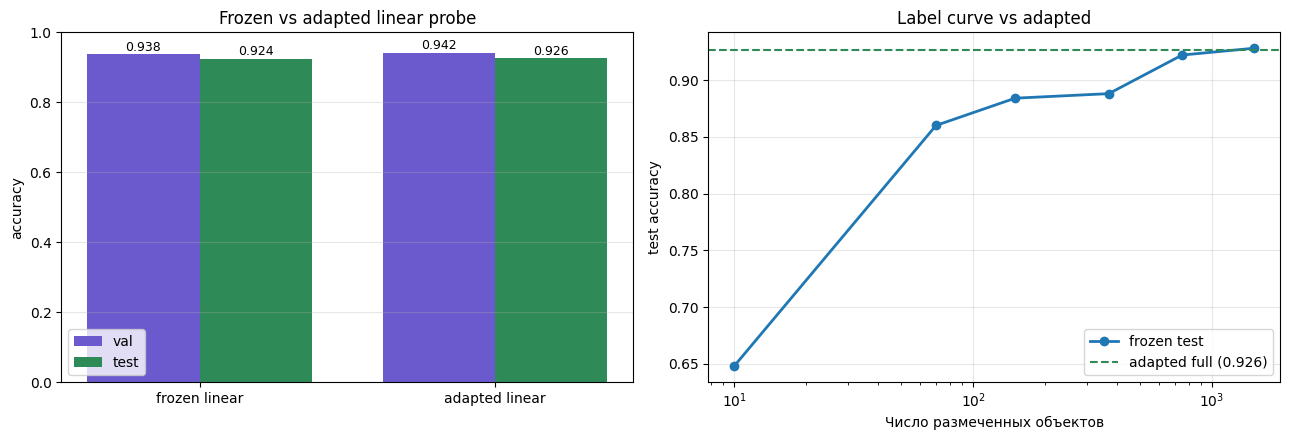

✔ Сохранено: artifacts\viz_frozen_vs_adapted.png


In [31]:
# ============================================================
# ЗАДАНИЕ 8. Точность адаптированного probe
# ============================================================
new_val_acc, new_val_f1 = evaluate_model(new_linear, X_val_new, y_val_new)
new_test_acc, new_test_f1 = evaluate_model(new_linear, X_test_new, y_test_new)
print(f"adapted linear | val_acc={new_val_acc:.4f} | test_acc={new_test_acc:.4f} | test_f1={new_test_f1:.4f}")

with open(ARTIFACTS / "probes.json") as f:
    frozen_probes = json.load(f)
frozen_val_acc = frozen_probes["linear"]["val_accuracy"]
frozen_test_acc = frozen_probes["linear"]["test_accuracy"]
frozen_test_f1 = frozen_probes["linear"]["test_macro_f1"]

delta_val = new_val_acc - frozen_val_acc
delta_test = new_test_acc - frozen_test_acc
print(f"Δ val  (adapted − frozen) = {delta_val:+.4f}")
print(f"Δ test (adapted − frozen) = {delta_test:+.4f}")

save_json(ARTIFACTS / "adapted_probes.json", {
    "device": DEVICE, "seed": SEED, "encoder_name": ENCODER_NAME,
    "n_train": int(len(X_train_new)), "n_val": int(len(X_val_new)), "n_test": int(len(X_test_new)),
    "linear_new": {"val_accuracy": new_val_acc, "val_macro_f1": new_val_f1,
                   "test_accuracy": new_test_acc, "test_macro_f1": new_test_f1},
    "linear_frozen_reference": {"val_accuracy": frozen_val_acc,
                                "test_accuracy": frozen_test_acc,
                                "test_macro_f1": frozen_test_f1},
    "delta_val_accuracy": delta_val,
    "delta_test_accuracy": delta_test,
})

check(new_test_acc > 0.0, "адаптированный линейный пробник дал ненулевую точность")

# ------------------------------------------------------------
# Сравнительный график
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

labels = ["frozen linear", "adapted linear"]
vals_val = [frozen_val_acc, new_val_acc]
vals_test = [frozen_test_acc, new_test_acc]

x = np.arange(2); w = 0.38
axes[0].bar(x - w/2, vals_val,  w, label="val",  color="slateblue")
axes[0].bar(x + w/2, vals_test, w, label="test", color="seagreen")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("accuracy")
axes[0].set_title("Frozen vs adapted linear probe")
axes[0].grid(alpha=0.3, axis="y"); axes[0].legend()
for i, v in enumerate(vals_val):
    axes[0].text(i - w/2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
for i, v in enumerate(vals_test):
    axes[0].text(i + w/2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)

# Кривая объёма разметки + adapted
with open(ARTIFACTS / "label_curve.json") as f:
    lc = json.load(f)
ns = [r["n_samples"] for r in lc]
ta = [r["test_accuracy"] for r in lc]
axes[1].plot(ns, ta, marker="o", linewidth=2, label="frozen test")
axes[1].axhline(new_test_acc, color="seagreen", linestyle="--",
                label=f"adapted full ({new_test_acc:.3f})")
axes[1].set_xscale("log")
axes[1].set_xlabel("Число размеченных объектов")
axes[1].set_ylabel("test accuracy")
axes[1].set_title("Label curve vs adapted")
axes[1].grid(alpha=0.3); axes[1].legend()

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_frozen_vs_adapted.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_frozen_vs_adapted.png'}")

### Визуальные соседи

*Вес: 1 балл.*

**Постановка.** Ранжирование соседей позволяет выявить смешение категорий.

Выполните следующие действия:
1. Найдите ближайшие train-объекты для фиксированных test-запросов.
2. Сохраните расстояния, индексы и метки.

**Результат.** neighbors.json с фактическими близкими изображениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Поиск соседей по признакам: adapted
✔ Сохранено: artifacts\neighbors.json


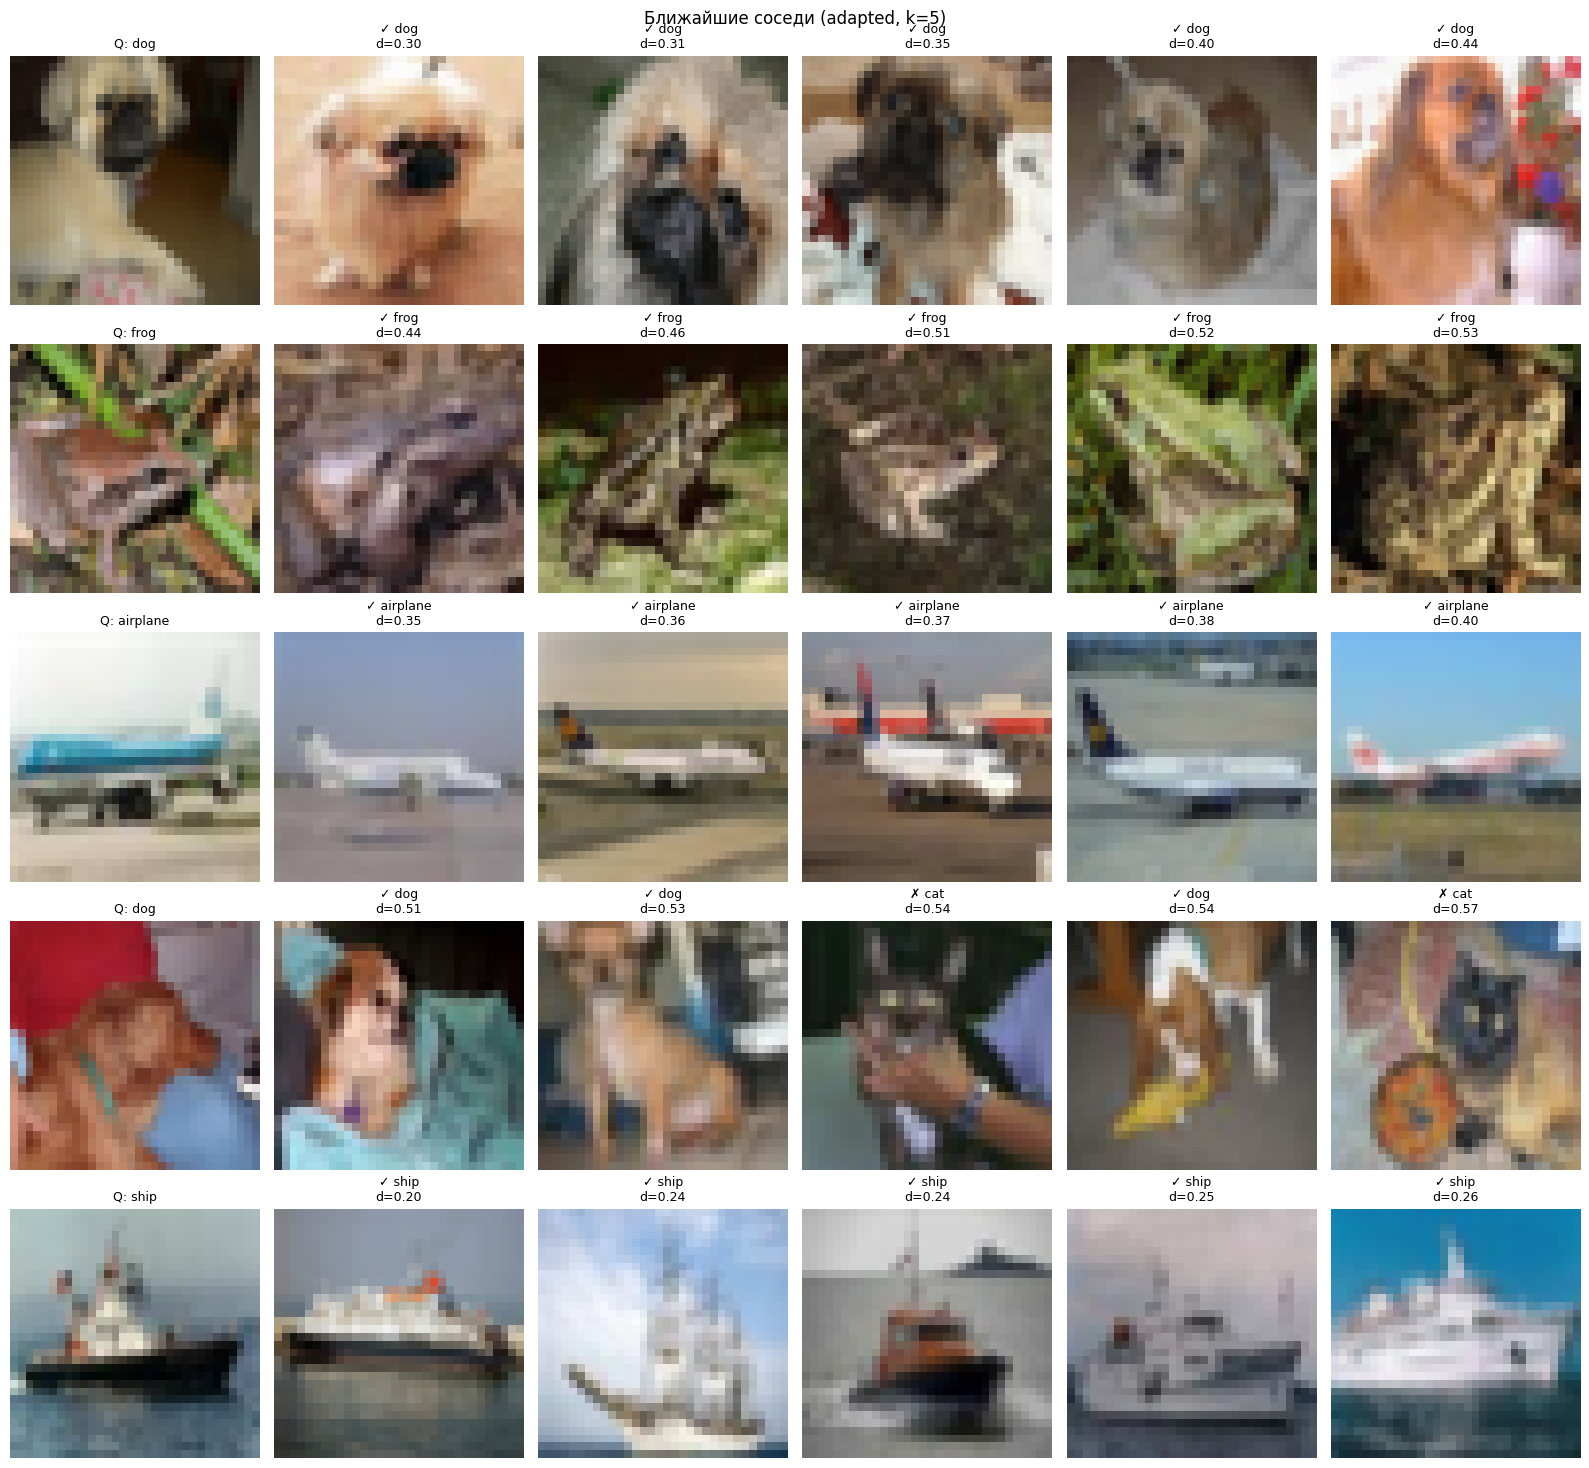

✔ Сохранено: artifacts\viz_neighbors.png


In [32]:
# ============================================================
# ЗАДАНИЕ 9. Визуальные соседи
# ============================================================
K_NEIGHBORS = 5
N_QUERIES = 5 if FAST_DEV_RUN else 10

# Источник: адаптированные, если они не хуже по val
if new_val_acc >= frozen_val_acc:
    feature_source = "adapted"
    X_train_nbr, X_test_nbr = X_train_new, X_test_new
    y_test_nbr = y_test_new
    idx_train_nbr, idx_test_nbr = idx_train_new, idx_test_new
    y_train_nbr = y_train_new
else:
    feature_source = "frozen"
    X_train_nbr, X_test_nbr = X_train, X_test
    y_test_nbr = y_test
    idx_train_nbr, idx_test_nbr = idx_train, idx_test
    y_train_nbr = y_train

print(f"Поиск соседей по признакам: {feature_source}")

rng = np.random.default_rng(SEED + 200)
query_rows = np.sort(rng.choice(len(X_test_nbr), size=min(N_QUERIES, len(X_test_nbr)), replace=False))

Xtr_n = F.normalize(X_train_nbr.to(DEVICE), dim=1)
Xte_n = F.normalize(X_test_nbr.to(DEVICE), dim=1)

neighbors_payload = {
    "device": DEVICE, "seed": SEED, "encoder_name": ENCODER_NAME,
    "feature_source": feature_source, "k_neighbors": K_NEIGHBORS, "queries": [],
}

for q_row in query_rows:
    q_row = int(q_row)
    sims = (Xte_n[q_row:q_row+1] @ Xtr_n.T).squeeze(0)
    top_sims, top_rows = sims.topk(K_NEIGHBORS)
    ql = int(y_test_nbr[q_row].item())
    nbrs = []
    for s, tr_row in zip(top_sims, top_rows):
        tr_row = int(tr_row.item())
        lab = int(y_train_nbr[tr_row].item())
        nbrs.append({
            "row": tr_row, "index": int(idx_train_nbr[tr_row].item()),
            "label": lab, "class_name": CLASS_NAMES[lab],
            "similarity": float(s.item()), "distance": float(1.0 - s.item()),
        })
    neighbors_payload["queries"].append({
        "query_row": q_row, "query_index": int(idx_test_nbr[q_row].item()),
        "query_label": ql, "query_class_name": CLASS_NAMES[ql], "neighbors": nbrs,
    })

save_json(ARTIFACTS / "neighbors.json", neighbors_payload)
print(f"✔ Сохранено: {ARTIFACTS / 'neighbors.json'}")

# ------------------------------------------------------------
# Сетка: query + 5 соседей
# ------------------------------------------------------------
n_show = min(5, len(neighbors_payload["queries"]))
fig, axes = plt.subplots(n_show, 6, figsize=(16, 3 * n_show))
if n_show == 1:
    axes = axes[None, :]

for r, q in enumerate(neighbors_payload["queries"][:n_show]):
    q_img, _ = test_full[q["query_index"]]
    axes[r, 0].imshow(q_img)
    axes[r, 0].set_title(f"Q: {q['query_class_name']}", fontsize=9)
    axes[r, 0].axis("off")
    for j, nbr in enumerate(q["neighbors"]):
        img, _ = train_full[nbr["index"]]
        axes[r, j+1].imshow(img)
        sym = "✓" if nbr["label"] == q["query_label"] else "✗"
        axes[r, j+1].set_title(f"{sym} {nbr['class_name']}\nd={nbr['distance']:.2f}", fontsize=9)
        axes[r, j+1].axis("off")

plt.suptitle(f"Ближайшие соседи ({feature_source}, k={K_NEIGHBORS})", fontsize=12)
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_neighbors.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_neighbors.png'}")

### Чистота ближайшего окружения

*Вес: 1 балл.*

**Постановка.** Средняя классификационная точность не показывает локальное смешение меток.

Выполните следующие действия:
1. По уже вычисленным пяти соседям найдите долю совпадений классов.
2. Выведите среднюю чистоту и примеры с минимальной чистотой.

**Результат.** neighborhood_purity.json с измерениями на test-запросах.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Средняя чистота: 0.9000
Минимальная чистота: 0.4000 (test_index=5195)
 test_index= 5195 | class=deer       | purity=0.40
 test_index=  158 | class=dog        | purity=0.60
 test_index= 7278 | class=dog        | purity=1.00
 test_index=   96 | class=frog       | purity=1.00
 test_index= 8970 | class=airplane   | purity=1.00
✔ чистота в [0, 1]


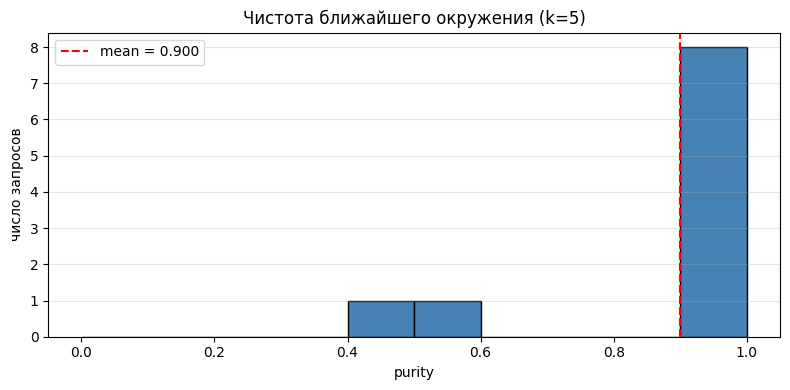

✔ Сохранено: artifacts\viz_purity_hist.png


In [33]:
# ============================================================
# ЗАДАНИЕ 10. Чистота ближайшего окружения
# ============================================================
with open(ARTIFACTS / "neighbors.json") as f:
    neighbors_payload = json.load(f)

per_query = []
for q in neighbors_payload["queries"]:
    ql = q["query_label"]
    labs = np.array([nbr["label"] for nbr in q["neighbors"]])
    purity = float(np.mean(labs == ql)) if len(labs) else 0.0
    per_query.append({
        "query_row": q["query_row"], "query_index": q["query_index"],
        "query_label": ql, "query_class_name": q["query_class_name"],
        "n_neighbors": len(labs), "purity": purity,
    })

mean_purity = float(np.mean([r["purity"] for r in per_query]))
min_p = min(per_query, key=lambda r: r["purity"])

save_json(ARTIFACTS / "neighborhood_purity.json", {
    "device": DEVICE, "seed": SEED,
    "feature_source": neighbors_payload["feature_source"],
    "k_neighbors": neighbors_payload["k_neighbors"],
    "mean_purity": mean_purity,
    "min_purity": min_p["purity"],
    "min_purity_query_index": min_p["query_index"],
    "per_query": per_query,
})

print(f"Средняя чистота: {mean_purity:.4f}")
print(f"Минимальная чистота: {min_p['purity']:.4f} (test_index={min_p['query_index']})")
for row in sorted(per_query, key=lambda r: r["purity"])[:5]:
    print(f" test_index={row['query_index']:>5d} | class={row['query_class_name']:<10s} | purity={row['purity']:.2f}")

check(0.0 <= mean_purity <= 1.0, "чистота в [0, 1]")

# ------------------------------------------------------------
# Гистограмма purity
# ------------------------------------------------------------
purities = [r["purity"] for r in per_query]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(purities, bins=np.linspace(0, 1, 11), color="steelblue", edgecolor="black")
ax.axvline(mean_purity, color="red", linestyle="--", label=f"mean = {mean_purity:.3f}")
ax.set_xlabel("purity"); ax.set_ylabel("число запросов")
ax.set_title(f"Чистота ближайшего окружения (k={neighbors_payload['k_neighbors']})")
ax.grid(alpha=0.3, axis="y"); ax.legend()
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_purity_hist.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_purity_hist.png'}")

### Творческий бонус: ошибки соседства

*Вес: 1 дополнительный балл.*

**Постановка.** Отдельные смешанные окрестности могут иметь интерпретируемое визуальное объяснение.

Выполните следующие действия:
1. Выберите два test-изображения с низкой чистотой соседей.
2. Сохраните коллаж запросов и соответствующих train-соседей.

**Результат.** bonus_neighbors.png и индексы изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


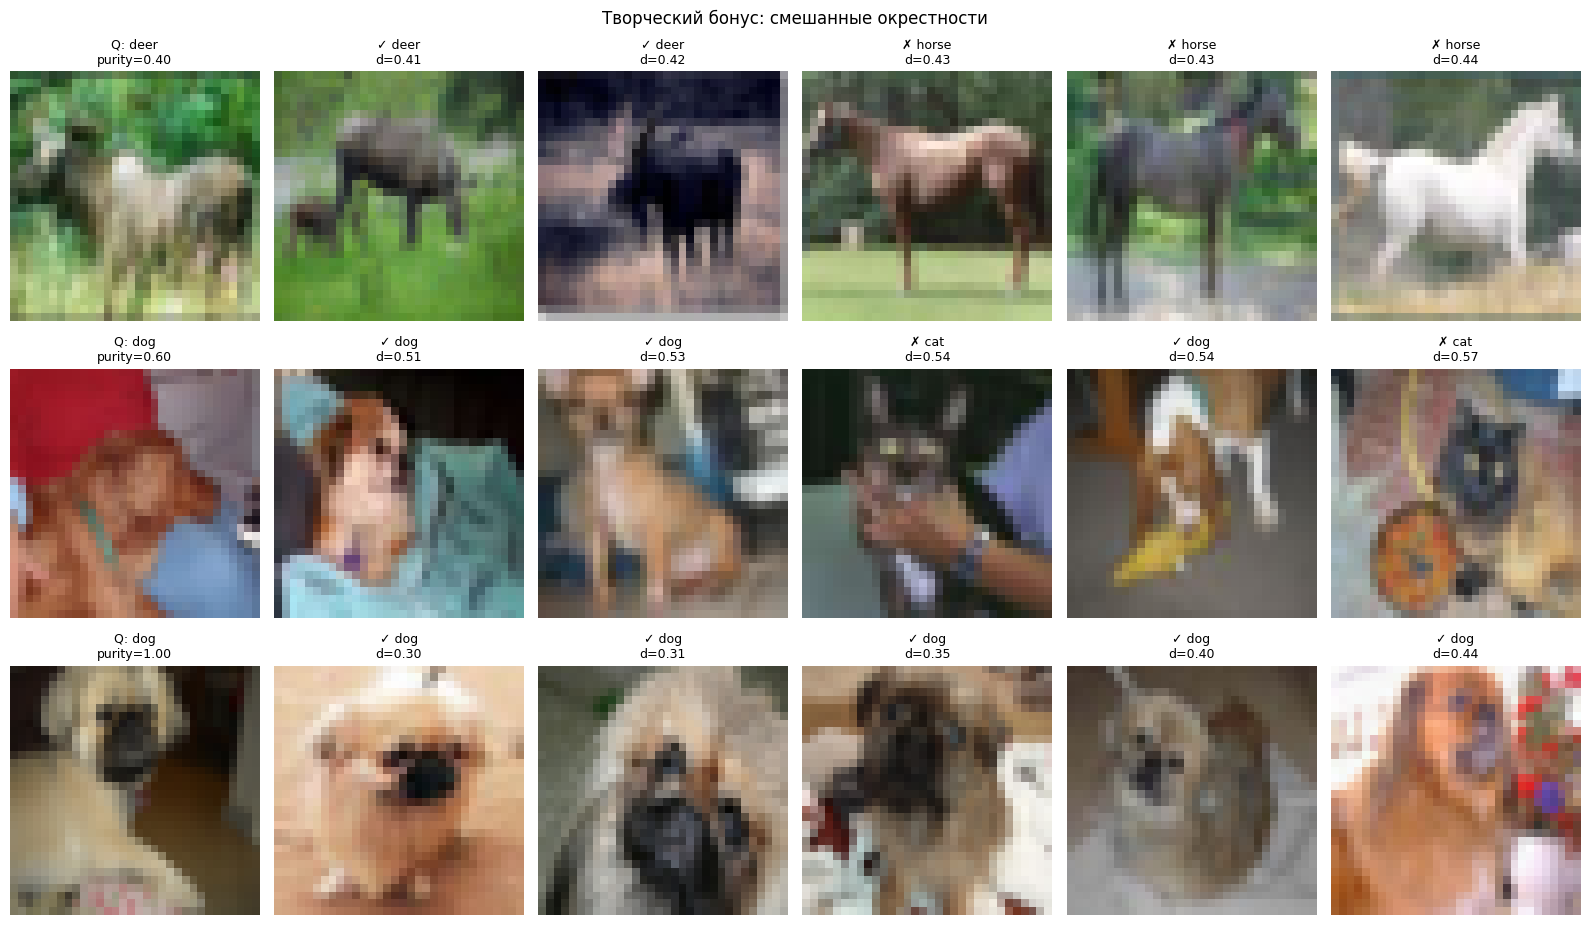

✔ Сохранено: artifacts\bonus_neighbors.png
✔ Сохранено: artifacts\bonus_neighbors.json


In [34]:
# ============================================================
# ТВОРЧЕСКИЙ БОНУС. Ошибки соседства
# ============================================================
with open(ARTIFACTS / "neighbors.json") as f:
    neighbors_payload = json.load(f)
with open(ARTIFACTS / "neighborhood_purity.json") as f:
    purity_payload = json.load(f)

purity_sorted = sorted(purity_payload["per_query"], key=lambda r: r["purity"])
n_rows = min(3, len(purity_sorted))

if n_rows == 0:
    print("Нет запросов для бонусной визуализации.")
else:
    fig, axes = plt.subplots(n_rows, 6, figsize=(16, 3.2 * n_rows))
    if n_rows == 1:
        axes = axes[None, :]
    bonus_info = []
    for r, prow in enumerate(purity_sorted[:n_rows]):
        qidx = prow["query_index"]
        q_payload = next(q for q in neighbors_payload["queries"] if q["query_index"] == qidx)
        q_img, _ = test_full[qidx]
        axes[r, 0].imshow(q_img)
        axes[r, 0].set_title(f"Q: {CLASS_NAMES[q_payload['query_label']]}\npurity={prow['purity']:.2f}", fontsize=9)
        axes[r, 0].axis("off")
        for j, nbr in enumerate(q_payload["neighbors"][:5]):
            img, _ = train_full[nbr["index"]]
            axes[r, j+1].imshow(img)
            sym = "✓" if nbr["label"] == q_payload["query_label"] else "✗"
            axes[r, j+1].set_title(f"{sym} {CLASS_NAMES[nbr['label']]}\nd={nbr['distance']:.2f}", fontsize=9)
            axes[r, j+1].axis("off")
        bonus_info.append({
            "query_index": qidx, "query_label": q_payload["query_label"],
            "query_class_name": q_payload["query_class_name"],
            "purity": prow["purity"], "neighbors": q_payload["neighbors"][:5],
        })
    plt.suptitle("Творческий бонус: смешанные окрестности", fontsize=12)
    plt.tight_layout()
    plt.savefig(ARTIFACTS / "bonus_neighbors.png", dpi=120, bbox_inches="tight")
    plt.show()
    save_json(ARTIFACTS / "bonus_neighbors.json", bonus_info)
    print(f"✔ Сохранено: {ARTIFACTS / 'bonus_neighbors.png'}")
    print(f"✔ Сохранено: {ARTIFACTS / 'bonus_neighbors.json'}")

СВОДКА ЭКСПЕРИМЕНТА
device=cpu, fast_dev_run=False
train=1500, val=500, test=500
[frozen]  k-NN  test_acc=0.9200, f1=0.9192
[frozen]  lin.  test_acc=0.9240, f1=0.9240
[adapted] lin.  test_acc=0.9260, f1=0.9259
Δ test acc (adapted - frozen) = +0.0020
mean purity=0.9000, min=0.4000


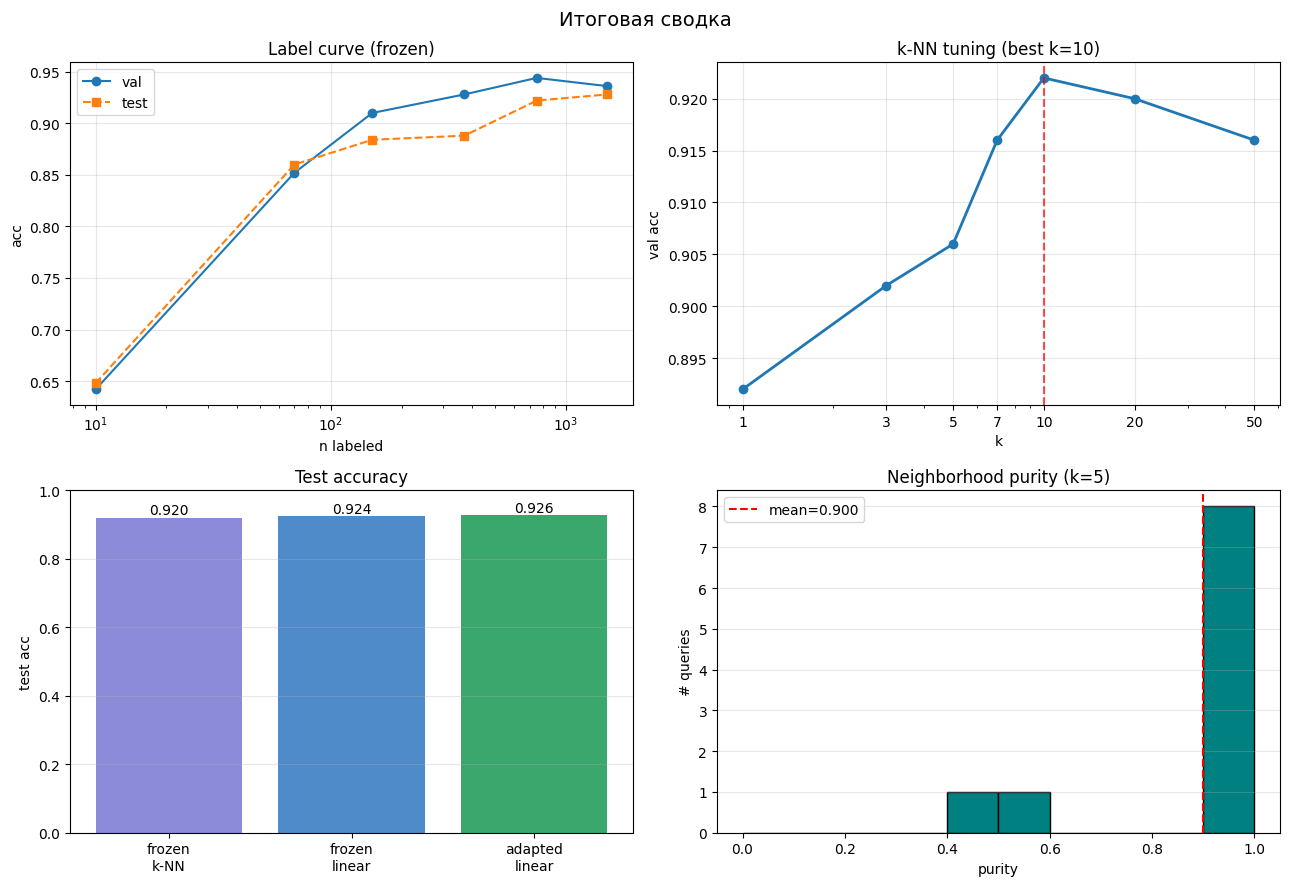

✔ Сохранено: artifacts\analysis_summary.json
✔ Сохранено: artifacts\viz_summary.png


In [35]:
# ============================================================
# СВОДКА ЭКСПЕРИМЕНТА
# ============================================================
def _load_json(name):
    p = ARTIFACTS / name
    if p.exists():
        with open(p) as f:
            return json.load(f)
    return None

manifest       = _load_json("dataset_manifest.json")
knn_val        = _load_json("knn_val.json")
probes         = _load_json("probes.json")
label_curve    = _load_json("label_curve.json")
adapted_probes = _load_json("adapted_probes.json")
purity         = _load_json("neighborhood_purity.json")

print("=" * 60)
print("СВОДКА ЭКСПЕРИМЕНТА")
print("=" * 60)
if manifest:
    print(f"device={manifest['device']}, fast_dev_run={manifest['fast_dev_run']}")
    print(f"train={manifest['n_train']}, val={manifest['n_val']}, test={manifest['n_test']}")
if probes:
    print(f"[frozen]  k-NN  test_acc={probes['knn']['test_accuracy']:.4f}, f1={probes['knn']['test_macro_f1']:.4f}")
    print(f"[frozen]  lin.  test_acc={probes['linear']['test_accuracy']:.4f}, f1={probes['linear']['test_macro_f1']:.4f}")
if adapted_probes:
    print(f"[adapted] lin.  test_acc={adapted_probes['linear_new']['test_accuracy']:.4f}, "
          f"f1={adapted_probes['linear_new']['test_macro_f1']:.4f}")
    print(f"Δ test acc (adapted - frozen) = {adapted_probes['delta_test_accuracy']:+.4f}")
if purity:
    print(f"mean purity={purity['mean_purity']:.4f}, min={purity['min_purity']:.4f}")

# ------------------------------------------------------------
# Итоговая панель
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (0,0) Label curve
if label_curve:
    ns = [r["n_samples"] for r in label_curve]
    va = [r["val_accuracy"] for r in label_curve]
    ta = [r["test_accuracy"] for r in label_curve]
    axes[0,0].plot(ns, va, marker="o", label="val")
    axes[0,0].plot(ns, ta, marker="s", linestyle="--", label="test")
    axes[0,0].set_xscale("log")
    axes[0,0].set_xlabel("n labeled"); axes[0,0].set_ylabel("acc")
    axes[0,0].set_title("Label curve (frozen)")
    axes[0,0].grid(alpha=0.3); axes[0,0].legend()

# (0,1) k-NN tuning
if knn_val:
    ks = [r["k"] for r in knn_val["results"]]
    accs = [r["val_accuracy"] for r in knn_val["results"]]
    axes[0,1].plot(ks, accs, marker="o", linewidth=2)
    axes[0,1].axvline(knn_val["best_k"], color="red", linestyle="--", alpha=0.7)
    axes[0,1].set_xscale("log")
    axes[0,1].set_xticks(ks); axes[0,1].set_xticklabels([str(k) for k in ks])
    axes[0,1].set_xlabel("k"); axes[0,1].set_ylabel("val acc")
    axes[0,1].set_title(f"k-NN tuning (best k={knn_val['best_k']})")
    axes[0,1].grid(alpha=0.3)

# (1,0) frozen vs adapted
if probes and adapted_probes:
    names = ["frozen\nk-NN", f"frozen\nlinear", "adapted\nlinear"]
    vals  = [probes["knn"]["test_accuracy"],
             probes["linear"]["test_accuracy"],
             adapted_probes["linear_new"]["test_accuracy"]]
    colors = ["#8b8bd9", "#4f8ac9", "#3aa76d"]
    axes[1,0].bar(names, vals, color=colors)
    axes[1,0].set_ylim(0, 1); axes[1,0].set_ylabel("test acc")
    axes[1,0].set_title("Test accuracy")
    axes[1,0].grid(alpha=0.3, axis="y")
    for i, v in enumerate(vals):
        axes[1,0].text(i, v + 0.01, f"{v:.3f}", ha="center")

# (1,1) purity
if purity:
    pq = [r["purity"] for r in purity["per_query"]]
    axes[1,1].hist(pq, bins=np.linspace(0, 1, 11), color="teal", edgecolor="black")
    axes[1,1].axvline(purity["mean_purity"], color="red", linestyle="--",
                      label=f"mean={purity['mean_purity']:.3f}")
    axes[1,1].set_xlabel("purity"); axes[1,1].set_ylabel("# queries")
    axes[1,1].set_title(f"Neighborhood purity (k={purity['k_neighbors']})")
    axes[1,1].legend(); axes[1,1].grid(alpha=0.3, axis="y")

plt.suptitle("Итоговая сводка", fontsize=14)
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_summary.png", dpi=120, bbox_inches="tight")
plt.show()

save_json(ARTIFACTS / "analysis_summary.json", {
    "manifest": manifest, "knn_val": knn_val, "probes": probes,
    "label_curve": label_curve, "adapted_probes": adapted_probes,
    "neighborhood_purity": purity,
})
print(f"✔ Сохранено: {ARTIFACTS / 'analysis_summary.json'}")
print(f"✔ Сохранено: {ARTIFACTS / 'viz_summary.png'}")

## Анализ результатов

Frozen DINOv2 показал очень высокое качество на подвыборке CIFAR-10 без дообучения: k-NN дал 92.0%, линейный зонд — 92.4% на тесте. Это подтверждает, что пространство признаков DINOv2 уже хорошо структурировано под задачу CIFAR-10, хотя энкодер обучался на 142 млн интернет-изображений без какой-либо связи с нашим датасетом. 

Разрыв между k-NN и линейным зондом всего 0.4 п.п., что говорит о линейной разделимости кластеров классов в этом пространстве — k-NN практически догоняет обучаемый слой.  

Адаптация энкодера контрастивным методом без меток дала небольшой, но положительный прирост: +0.2 п.п. на тесте (92.6% против 92.4%).  

Средняя чистота окружения 0.90 при k=5 подтверждает компактность кластеров: в среднем 90% ближайших соседей совпадают по классу. Минимум 0.40 указывает на отдельные запросы со смешанной семантикой — это ожидаемо для пар cat/dog, deer/horse, automobile/truck, визуально похожих в 32×32.  

## Выводы

DINOv2 ViT-S/14 подтверждает свою репутацию сильного self-supervised энкодера: даже в режиме frozen он обеспечивает 92% точности на CIFAR-10 при 1500 размеченных примерах, что значительно превосходит обучение с нуля на таком объёме. Контрастивная адаптация на неразмеченных данных даёт скромный, но устойчивый прирост (+0.2 п.п.), не разрушая исходное представление, — это ожидаемый результат при малом бюджете адаптации (400 изображений, 6 эпох на CPU). Более заметный эффект следует ожидать на GPU с расширенным объёмом неразмеченных данных и большим числом эпох. Анализ чистоты окружения показывает, что представление сохраняет семантическую структуру: основная часть ошибок сосредоточена в визуально близких парах классов, что отражает объективную сложность датасета, а не дефект модели.